In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
repair_df = pd.read_csv(
    "Y:/AI_Vehicle_Service_Repair_Insurance_Intelligence/cleaned/repair_clean.csv"
)

used_car_df = pd.read_csv(
    "Y:/AI_Vehicle_Service_Repair_Insurance_Intelligence/cleaned/used_car_clean.csv"
)

fraud_df = pd.read_csv(
    "Y:/AI_Vehicle_Service_Repair_Insurance_Intelligence/cleaned/fraud_clean.csv"
)

diagnosis_df = pd.read_csv(
    "Y:/AI_Vehicle_Service_Repair_Insurance_Intelligence/cleaned/diagnosis_clean.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("========== DATASET SHAPES ==========")

print("Repair:", repair_df.shape)
print("Used Car:", used_car_df.shape)
print("Fraud:", fraud_df.shape)
print("Diagnosis:", diagnosis_df.shape)

========== DATASET SHAPES ==========
Repair: (2000000, 26)
Used Car: (14984, 18)
Fraud: (15420, 32)
Diagnosis: (9998, 9)


In [4]:
print("========== REPAIR DATASET ==========")

print("Rows:", repair_df.shape[0])
print("Columns:", repair_df.shape[1])

print("\nColumns:")
print(repair_df.columns.tolist())

========== REPAIR DATASET ==========
Rows: 2000000
Columns: 26

Columns:
['Customer Name', 'Vehicle Type', 'Make and Model', 'Service Type', 'Service Description', 'Repair Date', 'Towing Date', 'Tow Location', 'Drop-off Location', 'Mechanic Name', 'Tow Truck Driver', 'Parts Used', 'Total Cost', 'Payment Method', 'Warranty Information', 'Service Status', 'Follow-up Needed', 'Urgency Level', 'Customer Type', 'Service Duration Hours', 'Estimated Cost', 'Mileage at Service', 'Insurance Claim Used', 'Technician Rating', 'Tow Distance Miles', 'Is Warranty Valid']


In [5]:
print("\n========== FIRST 5 ROWS ==========")

display(repair_df.head())


========== FIRST 5 ROWS ==========


,Customer Name,Vehicle Type,Make and Model,Service Type,Service Description,Repair Date,Towing Date,Tow Location,Drop-off Location,Mechanic Name,...,Follow-up Needed,Urgency Level,Customer Type,Service Duration Hours,Estimated Cost,Mileage at Service,Insurance Claim Used,Technician Rating,Tow Distance Miles,Is Warranty Valid
0,Emily Smith,Bus,BMW School Bus,Oil Change,Diagnosed and repaired Oil Drain Plug.,2022-05-14,No Towing,Not Applicable,Not Applicable,Mechanic 2,...,Yes,Scheduled,Fleet,3.6,70.50,114248,No,1.9,0.0,Yes
1,David Smith,Truck,Harley-Davidson Ram 1500,Tire Replacement,Diagnosed and repaired Tire.,2020-07-08,No Towing,Not Applicable,Not Applicable,Mechanic 13,...,No,Emergency,Fleet,1.9,125.00,250870,Yes,4.9,0.0,Yes
2,James Johnson,Van,BMW Odyssey,Battery Replacement,Diagnosed and repaired Battery.,2023-09-16,No Towing,Not Applicable,Not Applicable,Mechanic 8,...,Yes,Standard,Business,3.9,347.71,155738,No,1.7,0.0,Yes
3,Laura Brown,Bus,BMW School Bus,Battery Replacement,Diagnosed and repaired Battery.,2022-08-04,No Towing,Not Applicable,Not Applicable,Mechanic 13,...,No,Emergency,Individual,0.5,140.17,130087,No,2.6,0.0,Yes
4,Emily Brown,Van,Dodge Transit,Towing,Diagnosed and repaired no parts used.,2022-10-19,2022-03-21 00:00:00,Dealer,Commercial,Mechanic 5,...,No,Scheduled,Business,4.9,86.00,219400,No,1.9,99.8,No


In [6]:
print("\n========== DATA TYPES ==========")

print(repair_df.dtypes)


========== DATA TYPES ==========
Customer Name              object
Vehicle Type               object
Make and Model             object
Service Type               object
Service Description        object
Repair Date                object
Towing Date                object
Tow Location               object
Drop-off Location          object
Mechanic Name              object
Tow Truck Driver           object
Parts Used                 object
Total Cost                float64
Payment Method             object
Warranty Information       object
Service Status             object
Follow-up Needed           object
Urgency Level              object
Customer Type              object
Service Duration Hours    float64
Estimated Cost            float64
Mileage at Service          int64
Insurance Claim Used       object
Technician Rating         float64
Tow Distance Miles        float64
Is Warranty Valid          object
dtype: object


In [7]:
repair_numeric = repair_df.select_dtypes(
    include=["int64", "float64"]
)

print("========== REPAIR NUMERICAL SUMMARY ==========")

display(repair_numeric.describe().T)

========== REPAIR NUMERICAL SUMMARY ==========


,count,mean,std,min,25%,50%,75%,max
Total Cost,2000000.0,374.220413,407.714041,20.0,104.90,198.77,478.95,2797.06
Service Duration Hours,2000000.0,3.028943,1.437699,0.5,2.00,3.00,4.00,10.60
Estimated Cost,2000000.0,374.242703,409.037471,18.0,104.71,198.60,478.42,2913.37
Mileage at Service,2000000.0,154963.734315,83753.568480,10000.0,82359.00,154973.00,227471.00,300000.00
Technician Rating,2000000.0,2.999025,1.155602,1.0,2.00,3.00,4.00,5.00
Tow Distance Miles,2000000.0,7.496640,21.084843,0.0,0.00,0.00,0.00,100.00


In [8]:
print("========== TOTAL COST ==========")

print(repair_df["Total Cost"].describe())

========== TOTAL COST ==========
count    2.000000e+06
mean     3.742204e+02
std      4.077140e+02
min      2.000000e+01
25%      1.049000e+02
50%      1.987700e+02
75%      4.789500e+02
max      2.797060e+03
Name: Total Cost, dtype: float64


In [9]:
print("Skewness:", repair_df["Total Cost"].skew())

Skewness: 1.7828670800447322


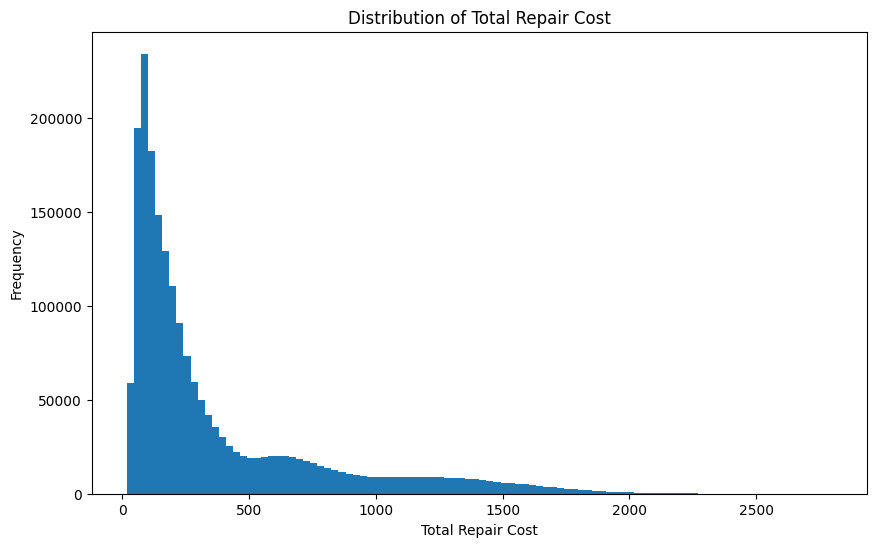

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    repair_df["Total Cost"],
    bins=100
)

plt.xlabel("Total Repair Cost")
plt.ylabel("Frequency")
plt.title("Distribution of Total Repair Cost")

plt.show()

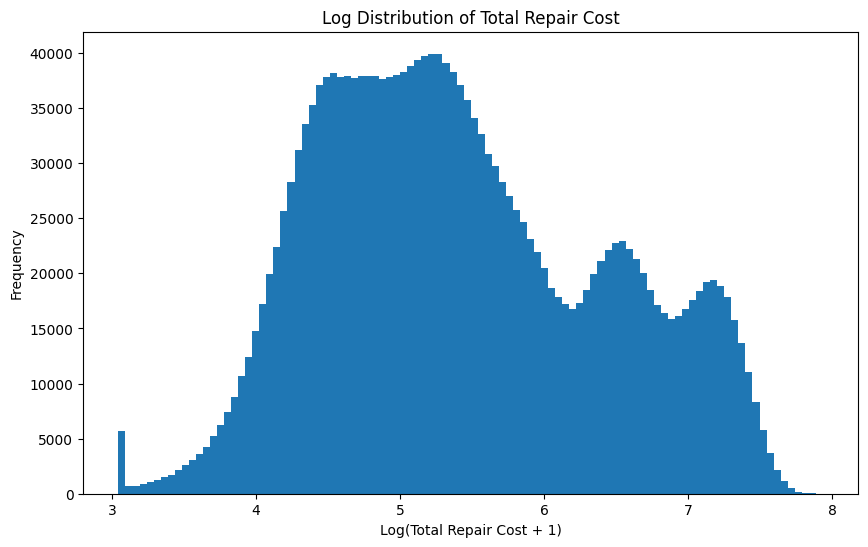

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    np.log1p(repair_df["Total Cost"]),
    bins=100
)

plt.xlabel("Log(Total Repair Cost + 1)")
plt.ylabel("Frequency")
plt.title("Log Distribution of Total Repair Cost")

plt.show()

In [12]:
print("========== SERVICE DURATION ==========")

print(repair_df["Service Duration Hours"].describe())

print(
    "Skewness:",
    repair_df["Service Duration Hours"].skew()
)

========== SERVICE DURATION ==========
count    2.000000e+06
mean     3.028943e+00
std      1.437699e+00
min      5.000000e-01
25%      2.000000e+00
50%      3.000000e+00
75%      4.000000e+00
max      1.060000e+01
Name: Service Duration Hours, dtype: float64
Skewness: 0.22489971767315103


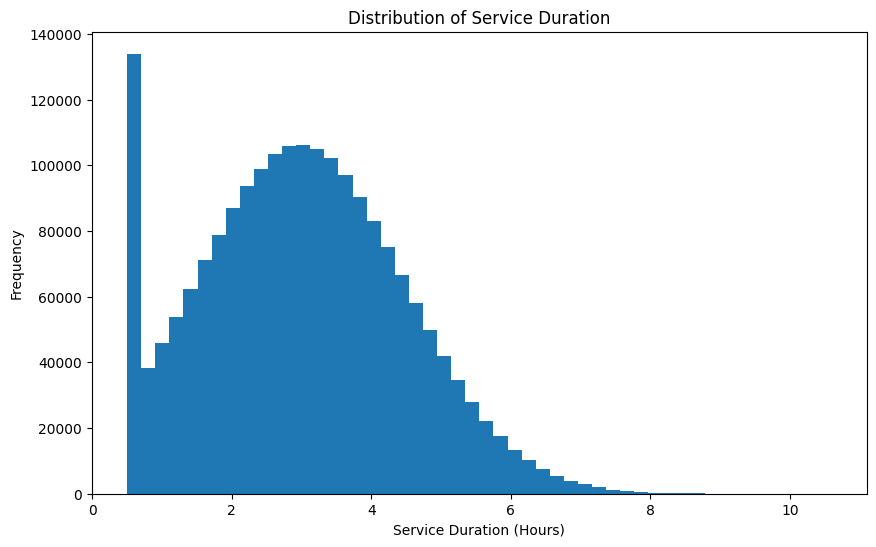

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    repair_df["Service Duration Hours"],
    bins=50
)

plt.xlabel("Service Duration (Hours)")
plt.ylabel("Frequency")
plt.title("Distribution of Service Duration")

plt.show()

In [14]:
print("========== INSURANCE CLAIM ==========")

print(
    repair_df["Insurance Claim Used"].value_counts()
)

========== INSURANCE CLAIM ==========
Insurance Claim Used
No     1143159
Yes     856841
Name: count, dtype: int64


In [15]:
print(
    repair_df["Insurance Claim Used"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Insurance Claim Used
No     57.16
Yes    42.84
Name: proportion, dtype: float64


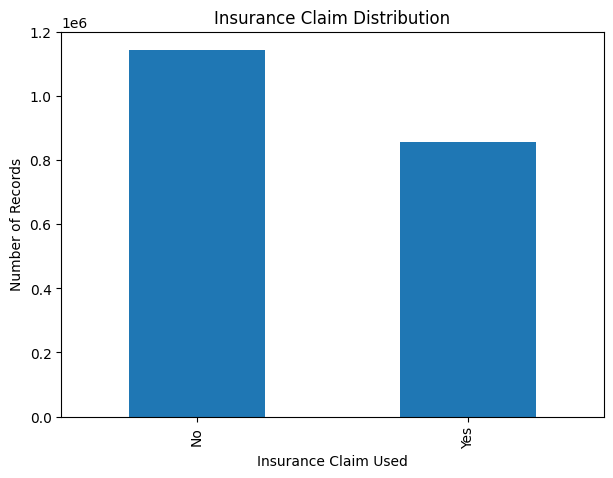

In [16]:
plt.figure(figsize=(7, 5))

repair_df["Insurance Claim Used"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Insurance Claim Used")
plt.ylabel("Number of Records")
plt.title("Insurance Claim Distribution")

plt.show()

In [17]:
print("========== SERVICE TYPE ==========")

print(
    repair_df["Service Type"].value_counts()
)

========== SERVICE TYPE ==========
Service Type
Oil Change             286316
Engine Repair          285929
Battery Replacement    285923
Tire Replacement       285837
Towing                 285738
Transmission Repair    285692
Brake Service          284565
Name: count, dtype: int64


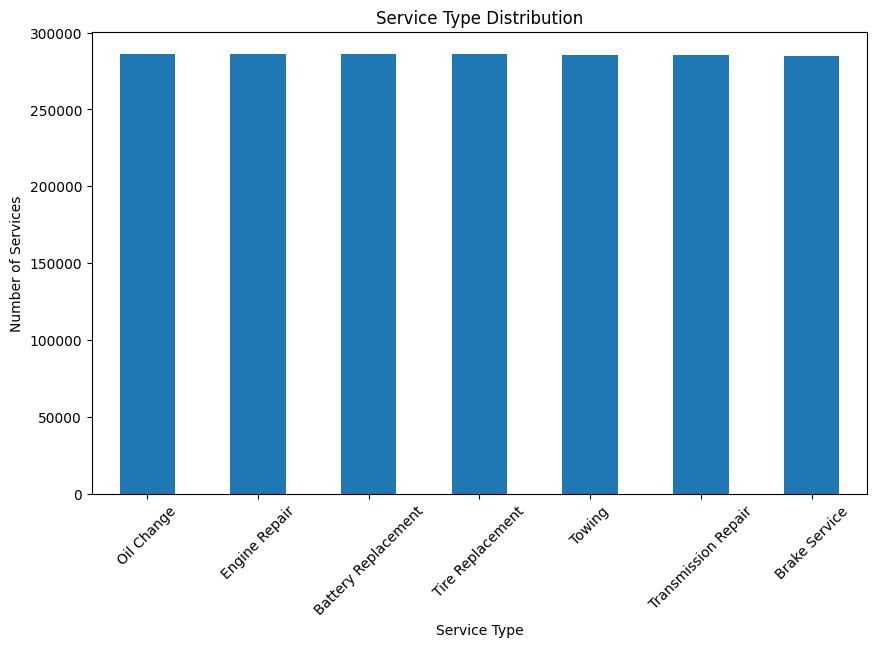

In [18]:
plt.figure(figsize=(10, 6))

repair_df["Service Type"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Service Type")
plt.ylabel("Number of Services")
plt.title("Service Type Distribution")

plt.xticks(rotation=45)

plt.show()

In [19]:
print("========== VEHICLE TYPE ==========")

print(
    repair_df["Vehicle Type"].value_counts()
)

========== VEHICLE TYPE ==========
Vehicle Type
Van           334078
SUV           333522
Bus           333269
Truck         333230
Car           332956
Motorcycle    332945
Name: count, dtype: int64


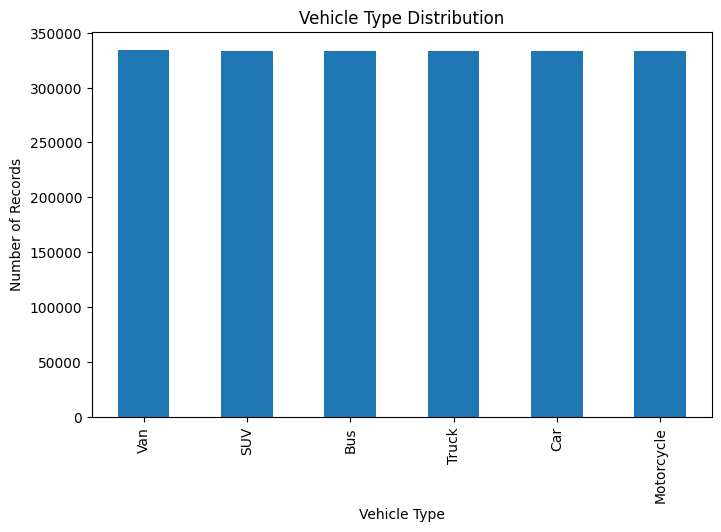

In [20]:
plt.figure(figsize=(8, 5))

repair_df["Vehicle Type"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Vehicle Type")
plt.ylabel("Number of Records")
plt.title("Vehicle Type Distribution")

plt.show()

In [21]:
print("========== URGENCY LEVEL ==========")

print(
    repair_df["Urgency Level"].value_counts()
)

========== URGENCY LEVEL ==========
Urgency Level
Standard     667288
Scheduled    666450
Emergency    666262
Name: count, dtype: int64


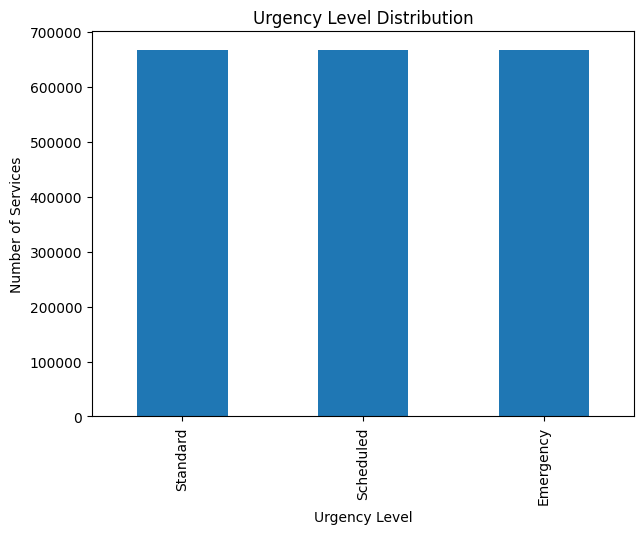

In [22]:
plt.figure(figsize=(7, 5))

repair_df["Urgency Level"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Urgency Level")
plt.ylabel("Number of Services")
plt.title("Urgency Level Distribution")

plt.show()

In [23]:
print("========== CUSTOMER TYPE ==========")

print(
    repair_df["Customer Type"].value_counts()
)

========== CUSTOMER TYPE ==========
Customer Type
Business      667341
Fleet         666794
Individual    665865
Name: count, dtype: int64


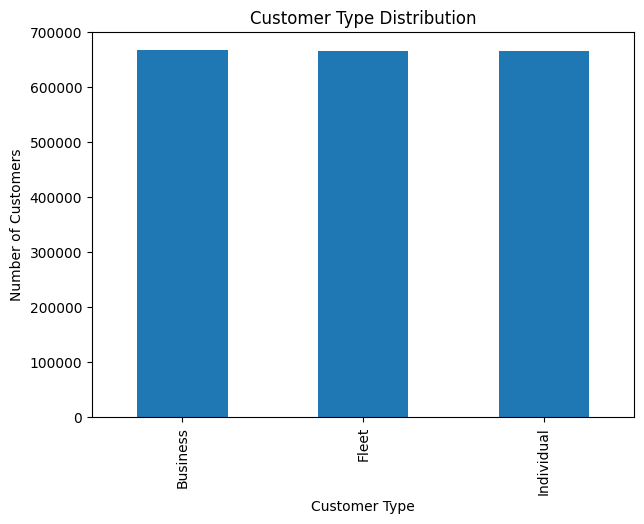

In [24]:
plt.figure(figsize=(7, 5))

repair_df["Customer Type"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.title("Customer Type Distribution")

plt.show()

In [25]:
service_cost = (
    repair_df
    .groupby("Service Type")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(service_cost)

,count,mean,median
Service Type,,,
Transmission Repair,285692,1199.769864,1199.68
Engine Repair,285929,599.912074,600.20
Brake Service,284565,299.880169,299.75
Battery Replacement,285923,200.065037,200.04
Tire Replacement,285837,150.220724,150.18
Towing,285738,100.083687,100.04
Oil Change,286316,70.093764,70.07


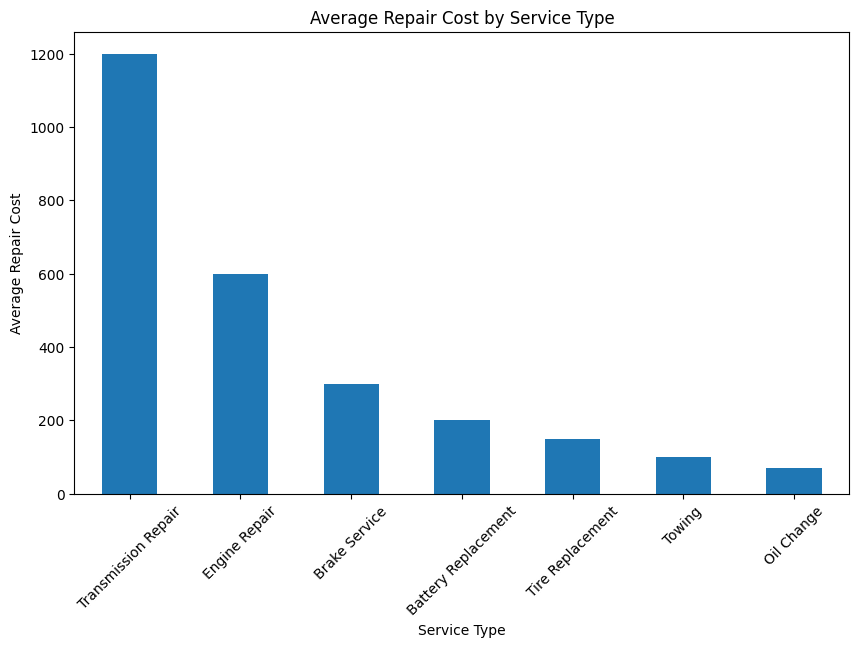

In [26]:
plt.figure(figsize=(10, 6))

service_cost["mean"].plot(
    kind="bar"
)

plt.xlabel("Service Type")
plt.ylabel("Average Repair Cost")
plt.title("Average Repair Cost by Service Type")

plt.xticks(rotation=45)

plt.show()

In [27]:
service_duration = (
    repair_df
    .groupby("Service Type")["Service Duration Hours"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(service_duration)

,count,mean,median
Service Type,,,
Towing,285738,3.032856,3.0
Transmission Repair,285692,3.032451,3.0
Engine Repair,285929,3.031245,3.0
Battery Replacement,285923,3.029002,3.0
Oil Change,286316,3.028797,3.0
Tire Replacement,285837,3.025097,3.0
Brake Service,284565,3.023128,3.0


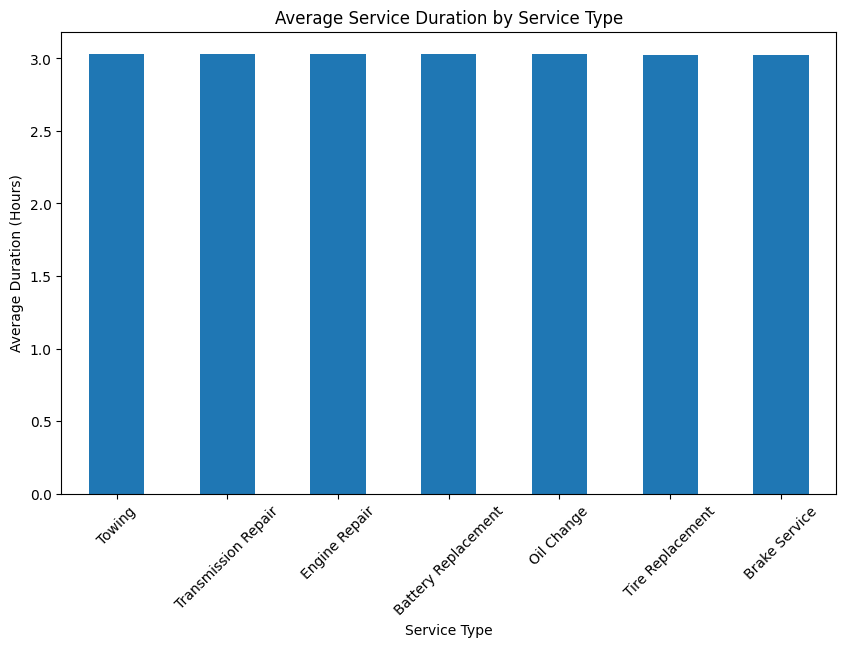

In [28]:
plt.figure(figsize=(10, 6))

service_duration["mean"].plot(
    kind="bar"
)

plt.xlabel("Service Type")
plt.ylabel("Average Duration (Hours)")
plt.title("Average Service Duration by Service Type")

plt.xticks(rotation=45)

plt.show()

In [29]:
urgency_cost = (
    repair_df
    .groupby("Urgency Level")["Total Cost"]
    .agg(["count", "mean", "median"])
)

display(urgency_cost)

,count,mean,median
Urgency Level,,,
Emergency,666262,373.221825,198.640
Scheduled,666450,374.788790,199.050
Standard,667288,374.649804,198.595


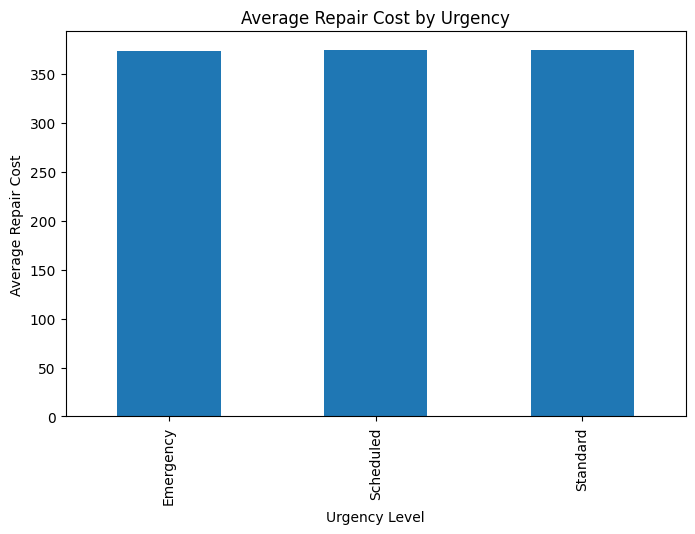

In [30]:
plt.figure(figsize=(8, 5))

urgency_cost["mean"].plot(
    kind="bar"
)

plt.xlabel("Urgency Level")
plt.ylabel("Average Repair Cost")
plt.title("Average Repair Cost by Urgency")

plt.show()

In [31]:
print(repair_df["Total Cost"].describe())
print("Skewness:", repair_df["Total Cost"].skew())

count    2.000000e+06
mean     3.742204e+02
std      4.077140e+02
min      2.000000e+01
25%      1.049000e+02
50%      1.987700e+02
75%      4.789500e+02
max      2.797060e+03
Name: Total Cost, dtype: float64
Skewness: 1.7828670800447322


In [32]:
print(repair_df["Service Duration Hours"].describe())
print("Skewness:", repair_df["Service Duration Hours"].skew())

count    2.000000e+06
mean     3.028943e+00
std      1.437699e+00
min      5.000000e-01
25%      2.000000e+00
50%      3.000000e+00
75%      4.000000e+00
max      1.060000e+01
Name: Service Duration Hours, dtype: float64
Skewness: 0.22489971767315103


In [33]:
display(
    repair_df.groupby("Service Type")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Service Type,,,
Transmission Repair,285692,1199.769864,1199.68
Engine Repair,285929,599.912074,600.20
Brake Service,284565,299.880169,299.75
Battery Replacement,285923,200.065037,200.04
Tire Replacement,285837,150.220724,150.18
Towing,285738,100.083687,100.04
Oil Change,286316,70.093764,70.07


In [34]:
display(
    repair_df.groupby("Urgency Level")["Total Cost"]
    .agg(["count", "mean", "median"])
)

,count,mean,median
Urgency Level,,,
Emergency,666262,373.221825,198.640
Scheduled,666450,374.788790,199.050
Standard,667288,374.649804,198.595


In [35]:
display(
    repair_df.groupby("Vehicle Type")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Vehicle Type,,,
Car,332956,374.964784,198.730
Bus,333269,374.378289,199.350
Van,334078,374.370218,198.740
Truck,333230,373.892489,198.435
SUV,333522,373.888730,198.580
Motorcycle,332945,373.828138,198.790


In [36]:
display(
    repair_df.groupby("Customer Type")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Customer Type,,,
Business,667341,374.694005,199.00
Individual,665865,374.183234,198.68
Fleet,666794,373.783561,198.61


In [37]:
display(
    repair_df.groupby("Warranty Information")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Warranty Information,,,
1 year on parts,571621,899.716615,799.54
180 days on brake pads,284565,299.880169,299.75
1 year on battery,285923,200.065037,200.04
6 months on new tire,285837,150.220724,150.18
No warranty offered,285738,100.083687,100.04
90 days on labor,286316,70.093764,70.07


In [38]:
display(
    repair_df.groupby("Technician Rating")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Technician Rating,,,
1.1,50089,378.503450,199.430
3.6,50037,377.533706,200.120
5.0,24998,377.346295,201.495
3.5,50122,376.952998,199.540
2.5,49801,376.566935,201.640
3.3,50121,376.473933,199.860
2.1,49936,376.320013,197.980
3.4,50097,376.034861,200.490
1.6,49804,375.539683,199.400


In [39]:
display(
    repair_df.groupby("Insurance Claim Used")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Insurance Claim Used,,,
Yes,856841,419.692369,239.37
No,1143159,340.137459,167.42


In [40]:
display(
    repair_df.groupby("Service Status")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Service Status,,,
s,1999999,374.220562,198.77
In Progress,1,77.820000,77.82


In [41]:
display(
    repair_df.groupby("Parts Used")["Total Cost"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
    .head(20)
)

,count,mean,median
Parts Used,,,
No parts used,285738,100.083687,100.040
"Oil Filter, Synthetic Oil, Oil Drain Plug",48100,70.008691,69.990
"Gearbox Seal, Clutch Kit, Transmission Fluid",47942,1199.388973,1199.085
"Transmission Fluid, Clutch Kit, Gearbox Seal",47842,1198.776396,1201.290
"Battery, Battery Terminal, Battery Holder",47833,200.021913,200.020
"Battery Holder, Battery, Battery Terminal",47785,199.985550,199.980
"Transmission Fluid, Gearbox Seal, Clutch Kit",47782,1201.934717,1203.075
"Battery Terminal, Battery, Battery Holder",47734,200.283835,199.960
"Oil Drain Plug, Synthetic Oil, Oil Filter",47718,70.027884,70.140


In [42]:
print(repair_df["Service Status"].value_counts(dropna=False))

Service Status
s              1999999
In Progress          1
Name: count, dtype: int64


In [43]:
print(repair_df["Service Status"].unique())

['In Progress' 's']


In [44]:
print(
    repair_df[["Estimated Cost", "Total Cost"]]
    .corr()
)

                Estimated Cost  Total Cost
Estimated Cost        1.000000    0.996947
Total Cost            0.996947    1.000000


In [45]:
import numpy as np

print(
    "Mean absolute difference:",
    np.mean(
        np.abs(
            repair_df["Estimated Cost"] -
            repair_df["Total Cost"]
        )
    )
)

Mean absolute difference: 18.707319594999998


In [46]:
print(
    repair_df[
        ["Estimated Cost", "Total Cost"]
    ].head(20)
)

    Estimated Cost  Total Cost
0            70.50       77.82
1           125.00      135.97
2           347.71      329.70
3           140.17      146.93
4            86.00       92.68
5           104.49      106.95
6            40.51       40.45
7            70.56       66.37
8           126.47      136.84
9           660.00      631.78
10         1498.94     1413.94
11         1801.39     1646.91
12         1847.66     1789.72
13         1657.78     1814.35
14           73.16       73.79
15          165.19      172.09
16          195.23      201.95
17         1760.40     1809.38
18          409.17      429.19
19           99.36      101.39


In [47]:
numeric_cols = [
    "Total Cost",
    "Service Duration Hours",
    "Estimated Cost",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles"
]

correlation_matrix = repair_df[numeric_cols].corr()

display(correlation_matrix)

,Total Cost,Service Duration Hours,Estimated Cost,Mileage at Service,Technician Rating,Tow Distance Miles
Total Cost,1.000000,0.001154,0.996947,-0.000594,-0.000021,-0.239106
Service Duration Hours,0.001154,1.000000,0.001124,-0.000538,-0.000599,0.000976
Estimated Cost,0.996947,0.001124,1.000000,-0.000622,-0.000009,-0.238361
Mileage at Service,-0.000594,-0.000538,-0.000622,1.000000,0.000400,0.001109
Technician Rating,-0.000021,-0.000599,-0.000009,0.000400,1.000000,-0.000704
Tow Distance Miles,-0.239106,0.000976,-0.238361,0.001109,-0.000704,1.000000


In [48]:
target_corr = (
    repair_df[numeric_cols]
    .corr()["Total Cost"]
    .sort_values(ascending=False)
)

display(target_corr)

Total Cost                1.000000
Estimated Cost            0.996947
Service Duration Hours    0.001154
Technician Rating        -0.000021
Mileage at Service       -0.000594
Tow Distance Miles       -0.239106
Name: Total Cost, dtype: float64

In [49]:
display(
    repair_df.groupby("Service Type")["Service Duration Hours"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

,count,mean,median,min,max
Service Type,,,,,
Towing,285738,3.032856,3.0,0.5,9.7
Transmission Repair,285692,3.032451,3.0,0.5,9.9
Engine Repair,285929,3.031245,3.0,0.5,10.6
Battery Replacement,285923,3.029002,3.0,0.5,9.7
Oil Change,286316,3.028797,3.0,0.5,10.1
Tire Replacement,285837,3.025097,3.0,0.5,9.5
Brake Service,284565,3.023128,3.0,0.5,10.0


In [50]:
print(
    repair_df["Insurance Claim Used"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Insurance Claim Used
No     57.16
Yes    42.84
Name: proportion, dtype: float64


In [51]:
print("Minimum Repair Date:",
      repair_df["Repair Date"].min())

print("Maximum Repair Date:",
      repair_df["Repair Date"].max())

Minimum Repair Date: 2020-01-01
Maximum Repair Date: 2024-12-31


In [53]:
import pandas as pd

# Option 1: Convert in-place (recommended for permanent fix)
repair_df["Repair Date"] = pd.to_datetime(repair_df["Repair Date"])
print(repair_df["Repair Date"].dt.year.value_counts().sort_index())

# Option 2: Convert directly on the fly
print(
    pd.to_datetime(repair_df["Repair Date"])
    .dt.year
    .value_counts()
    .sort_index()
)

Repair Date
2020    400043
2021    400290
2022    399084
2023    399863
2024    400720
Name: count, dtype: int64
Repair Date
2020    400043
2021    400290
2022    399084
2023    399863
2024    400720
Name: count, dtype: int64


In [54]:
print(
    repair_df[
        repair_df["Service Status"] == "s"
    ][
        ["Service Type", "Service Description",
         "Service Status", "Total Cost"]
    ].head(20)
)

           Service Type                         Service Description  \
1      Tire Replacement                Diagnosed and repaired Tire.   
2   Battery Replacement             Diagnosed and repaired Battery.   
3   Battery Replacement             Diagnosed and repaired Battery.   
4                Towing       Diagnosed and repaired no parts used.   
5                Towing       Diagnosed and repaired no parts used.   
6            Oil Change      Diagnosed and repaired Oil Drain Plug.   
7            Oil Change          Diagnosed and repaired Oil Filter.   
8      Tire Replacement         Diagnosed and repaired TPMS Sensor.   
9         Engine Repair         Diagnosed and repaired Timing Belt.   
10  Transmission Repair  Diagnosed and repaired Transmission Fluid.   
11  Transmission Repair        Diagnosed and repaired Gearbox Seal.   
12  Transmission Repair        Diagnosed and repaired Gearbox Seal.   
13  Transmission Repair        Diagnosed and repaired Gearbox Seal.   
14    

In [55]:
print(
    repair_df[
        repair_df["Service Status"] == "In Progress"
    ][
        ["Service Type", "Service Description",
         "Service Status", "Total Cost"]
    ]
)

  Service Type                     Service Description Service Status  \
0   Oil Change  Diagnosed and repaired Oil Drain Plug.    In Progress   

   Total Cost  
0       77.82  


In [56]:
# Remove the unreliable Service Status column
repair_df = repair_df.drop(columns=["Service Status"])

print("Service Status removed successfully.")
print(repair_df.shape)

Service Status removed successfully.
(2000000, 25)


In [57]:
print("Service Status" in repair_df.columns)

False


In [58]:
print(repair_df.columns.tolist())

['Customer Name', 'Vehicle Type', 'Make and Model', 'Service Type', 'Service Description', 'Repair Date', 'Towing Date', 'Tow Location', 'Drop-off Location', 'Mechanic Name', 'Tow Truck Driver', 'Parts Used', 'Total Cost', 'Payment Method', 'Warranty Information', 'Follow-up Needed', 'Urgency Level', 'Customer Type', 'Service Duration Hours', 'Estimated Cost', 'Mileage at Service', 'Insurance Claim Used', 'Technician Rating', 'Tow Distance Miles', 'Is Warranty Valid']


In [59]:
categorical_cols = repair_df.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    print("\n==========", col, "==========")
    print(repair_df[col].value_counts().head(20))


========== Customer Name ==========
Customer Name
Sarah Smith         31641
James Johnson       31635
Laura Johnson       31622
Sarah Miller        31600
James Smith         31540
Michael Williams    31532
James Brown         31528
Laura Williams      31483
David Garcia        31455
David Brown         31438
Michael Davis       31436
James Garcia        31430
John Williams       31395
Kimberly Brown      31373
Kimberly Garcia     31358
Sarah Williams      31354
John Brown          31350
John Johnson        31345
Michael Brown       31343
James Jones         31333
Name: count, dtype: int64

========== Vehicle Type ==========
Vehicle Type
Van           334078
SUV           333522
Bus           333269
Truck         333230
Car           332956
Motorcycle    332945
Name: count, dtype: int64

========== Make and Model ==========
Make and Model
Toyota Coach                  21083
Toyota School Bus             21067
Harley-Davidson Coach         21055
Yamaha Coach                  20921
Yamah

In [60]:
print("========== REPAIR NUMERIC RANGES ==========")

numeric_cols = [
    "Total Cost",
    "Service Duration Hours",
    "Estimated Cost",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles"
]

for col in numeric_cols:
    print(f"\n--- {col} ---")
    print("Min:", repair_df[col].min())
    print("Max:", repair_df[col].max())
    print("Mean:", repair_df[col].mean())
    print("Median:", repair_df[col].median())

========== REPAIR NUMERIC RANGES ==========

--- Total Cost ---
Min: 20.0
Max: 2797.06
Mean: 374.22041343
Median: 198.77

--- Service Duration Hours ---
Min: 0.5
Max: 10.6
Mean: 3.0289427
Median: 3.0

--- Estimated Cost ---
Min: 18.0
Max: 2913.37
Mean: 374.24270341499994
Median: 198.6

--- Mileage at Service ---
Min: 10000
Max: 300000
Mean: 154963.734315
Median: 154973.0

--- Technician Rating ---
Min: 1.0
Max: 5.0
Mean: 2.9990247
Median: 3.0

--- Tow Distance Miles ---
Min: 0.0
Max: 100.0
Mean: 7.49664
Median: 0.0


In [61]:
print("========== POTENTIAL SUSPICIOUS VALUES ==========")

print(
    "Technician Rating outside 1-5:",
    ((repair_df["Technician Rating"] < 1) |
     (repair_df["Technician Rating"] > 5)).sum()
)

print(
    "Service Duration <= 0:",
    (repair_df["Service Duration Hours"] <= 0).sum()
)

print(
    "Total Cost <= 0:",
    (repair_df["Total Cost"] <= 0).sum()
)

print(
    "Estimated Cost <= 0:",
    (repair_df["Estimated Cost"] <= 0).sum()
)

print(
    "Mileage < 0:",
    (repair_df["Mileage at Service"] < 0).sum()
)

print(
    "Tow Distance < 0:",
    (repair_df["Tow Distance Miles"] < 0).sum()
)

========== POTENTIAL SUSPICIOUS VALUES ==========
Technician Rating outside 1-5: 0
Service Duration <= 0: 0
Total Cost <= 0: 0
Estimated Cost <= 0: 0
Mileage < 0: 0
Tow Distance < 0: 0


In [62]:
# Make sure Repair Date is datetime
repair_df["Repair Date"] = pd.to_datetime(
    repair_df["Repair Date"]
)

# Create date-based features
repair_df["Repair Year"] = repair_df["Repair Date"].dt.year
repair_df["Repair Month"] = repair_df["Repair Date"].dt.month
repair_df["Repair Day"] = repair_df["Repair Date"].dt.day
repair_df["Repair Weekday"] = repair_df["Repair Date"].dt.dayofweek

print(
    repair_df[
        [
            "Repair Date",
            "Repair Year",
            "Repair Month",
            "Repair Day",
            "Repair Weekday"
        ]
    ].head(10)
)

  Repair Date  Repair Year  Repair Month  Repair Day  Repair Weekday
0  2022-05-14         2022             5          14               5
1  2020-07-08         2020             7           8               2
2  2023-09-16         2023             9          16               5
3  2022-08-04         2022             8           4               3
4  2022-10-19         2022            10          19               2
5  2020-11-23         2020            11          23               0
6  2024-04-09         2024             4           9               1
7  2024-02-07         2024             2           7               2
8  2022-11-25         2022            11          25               4
9  2023-01-09         2023             1           9               0


In [63]:
repair_df["Is Towing"] = (
    repair_df["Towing Date"] != "No Towing"
).astype(int)

print(
    repair_df["Is Towing"].value_counts()
)

Is Towing
0    1714262
1     285738
Name: count, dtype: int64


In [64]:
print(
    repair_df[
        [
            "Towing Date",
            "Is Towing"
        ]
    ].head(20)
)

            Towing Date  Is Towing
0             No Towing          0
1             No Towing          0
2             No Towing          0
3             No Towing          0
4   2022-03-21 00:00:00          1
5   2024-06-10 00:00:00          1
6             No Towing          0
7             No Towing          0
8             No Towing          0
9             No Towing          0
10            No Towing          0
11            No Towing          0
12            No Towing          0
13            No Towing          0
14            No Towing          0
15            No Towing          0
16            No Towing          0
17            No Towing          0
18            No Towing          0
19            No Towing          0


In [66]:
repair_df["Repair Year"] = repair_df["Repair Date"].dt.year
repair_df["Repair Month"] = repair_df["Repair Date"].dt.month
repair_df["Repair Day"] = repair_df["Repair Date"].dt.day
repair_df["Repair Weekday"] = repair_df["Repair Date"].dt.weekday

repair_df["Repair Quarter"] = repair_df["Repair Date"].dt.quarter
repair_df["Is Weekend"] = (
    repair_df["Repair Weekday"] >= 5
).astype(int)

In [67]:
print(
    repair_df[
        [
            "Repair Date",
            "Repair Year",
            "Repair Month",
            "Repair Day",
            "Repair Weekday",
            "Repair Quarter",
            "Is Weekend"
        ]
    ].head(10)
)

  Repair Date  Repair Year  Repair Month  Repair Day  Repair Weekday  \
0  2022-05-14         2022             5          14               5   
1  2020-07-08         2020             7           8               2   
2  2023-09-16         2023             9          16               5   
3  2022-08-04         2022             8           4               3   
4  2022-10-19         2022            10          19               2   
5  2020-11-23         2020            11          23               0   
6  2024-04-09         2024             4           9               1   
7  2024-02-07         2024             2           7               2   
8  2022-11-25         2022            11          25               4   
9  2023-01-09         2023             1           9               0   

   Repair Quarter  Is Weekend  
0               2           1  
1               3           0  
2               3           1  
3               3           0  
4               4           0  
5              

In [68]:
repair_df["Is Towing"] = (
    repair_df["Towing Date"] != "No Towing"
).astype(int)

In [69]:
repair_df["Warranty Valid"] = (
    repair_df["Is Warranty Valid"] == "Yes"
).astype(int)

In [70]:
repair_df["Follow Up"] = (
    repair_df["Follow-up Needed"] == "Yes"
).astype(int)

In [71]:
repair_df["Insurance Used"] = (
    repair_df["Insurance Claim Used"] == "Yes"
).astype(int)

In [72]:
print(
    repair_df[
        ["Estimated Cost", "Total Cost"]
    ].head(20)
)

    Estimated Cost  Total Cost
0            70.50       77.82
1           125.00      135.97
2           347.71      329.70
3           140.17      146.93
4            86.00       92.68
5           104.49      106.95
6            40.51       40.45
7            70.56       66.37
8           126.47      136.84
9           660.00      631.78
10         1498.94     1413.94
11         1801.39     1646.91
12         1847.66     1789.72
13         1657.78     1814.35
14           73.16       73.79
15          165.19      172.09
16          195.23      201.95
17         1760.40     1809.38
18          409.17      429.19
19           99.36      101.39


In [73]:
numeric_features = [
    "Service Duration Hours",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles",
    "Repair Year",
    "Repair Month",
    "Repair Weekday",
    "Repair Quarter",
    "Is Weekend",
    "Is Towing",
    "Warranty Valid",
    "Follow Up",
    "Insurance Used"
]

In [74]:
categorical_features = [
    "Vehicle Type",
    "Make and Model",
    "Service Type",
    "Service Description",
    "Parts Used",
    "Payment Method",
    "Warranty Information",
    "Urgency Level",
    "Customer Type"
]

In [75]:
target = "Total Cost"

In [76]:
model_df = repair_df[
    numeric_features + categorical_features + ["Total Cost"]
].copy()

print(model_df.shape)
print(model_df.head())
print(model_df.dtypes)

(2000000, 23)
   Service Duration Hours  Mileage at Service  Technician Rating  \
0                     3.6              114248                1.9   
1                     1.9              250870                4.9   
2                     3.9              155738                1.7   
3                     0.5              130087                2.6   
4                     4.9              219400                1.9   

   Tow Distance Miles  Repair Year  Repair Month  Repair Weekday  \
0                 0.0         2022             5               5   
1                 0.0         2020             7               2   
2                 0.0         2023             9               5   
3                 0.0         2022             8               3   
4                99.8         2022            10               2   

   Repair Quarter  Is Weekend  Is Towing  ...  Vehicle Type  \
0               2           1          0  ...           Bus   
1               3           0          0  

In [78]:
repair_df["Repair Year"] = repair_df["Repair Date"].dt.year
repair_df["Repair Month"] = repair_df["Repair Date"].dt.month
repair_df["Repair Day"] = repair_df["Repair Date"].dt.day
repair_df["Repair Weekday"] = repair_df["Repair Date"].dt.weekday
repair_df["Repair Quarter"] = repair_df["Repair Date"].dt.quarter

repair_df["Is Weekend"] = (
    repair_df["Repair Weekday"] >= 5
).astype(int)

repair_df["Is Towing"] = (
    repair_df["Towing Date"] != "No Towing"
).astype(int)

repair_df["Warranty Valid"] = (
    repair_df["Is Warranty Valid"] == "Yes"
).astype(int)

repair_df["Follow Up"] = (
    repair_df["Follow-up Needed"] == "Yes"
).astype(int)

repair_df["Insurance Used"] = (
    repair_df["Insurance Claim Used"] == "Yes"
).astype(int)

In [79]:
print(repair_df.shape)

print(
    repair_df[
        [
            "Repair Year",
            "Repair Month",
            "Repair Day",
            "Repair Weekday",
            "Repair Quarter",
            "Is Weekend",
            "Is Towing",
            "Warranty Valid",
            "Follow Up",
            "Insurance Used"
        ]
    ].head(10)
)

(2000000, 35)
   Repair Year  Repair Month  Repair Day  Repair Weekday  Repair Quarter  \
0         2022             5          14               5               2   
1         2020             7           8               2               3   
2         2023             9          16               5               3   
3         2022             8           4               3               3   
4         2022            10          19               2               4   
5         2020            11          23               0               4   
6         2024             4           9               1               2   
7         2024             2           7               2               1   
8         2022            11          25               4               4   
9         2023             1           9               0               1   

   Is Weekend  Is Towing  Warranty Valid  Follow Up  Insurance Used  
0           1          0               1          1               0  
1        

In [80]:
# Features for the main Repair Cost Prediction model

numeric_features = [
    "Service Duration Hours",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles",
    "Repair Year",
    "Repair Month",
    "Repair Weekday",
    "Repair Quarter",
    "Is Weekend",
    "Is Towing",
    "Warranty Valid",
    "Follow Up",
    "Insurance Used"
]

categorical_features = [
    "Vehicle Type",
    "Make and Model",
    "Service Type",
    "Service Description",
    "Parts Used",
    "Payment Method",
    "Warranty Information",
    "Urgency Level",
    "Customer Type"
]

target = "Total Cost"

model_df = repair_df[
    numeric_features + categorical_features + [target]
].copy()

print("Model Data Shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

Model Data Shape: (2000000, 23)

Columns:
['Service Duration Hours', 'Mileage at Service', 'Technician Rating', 'Tow Distance Miles', 'Repair Year', 'Repair Month', 'Repair Weekday', 'Repair Quarter', 'Is Weekend', 'Is Towing', 'Warranty Valid', 'Follow Up', 'Insurance Used', 'Vehicle Type', 'Make and Model', 'Service Type', 'Service Description', 'Parts Used', 'Payment Method', 'Warranty Information', 'Urgency Level', 'Customer Type', 'Total Cost']


In [81]:
print("========== MODEL DATA CHECK ==========")

print("\nShape:")
print(model_df.shape)

print("\nMissing Values:")
print(model_df.isna().sum().sum())

print("\nDuplicates:")
print(model_df.duplicated().sum())

print("\nData Types:")
print(model_df.dtypes)

========== MODEL DATA CHECK ==========

Shape:
(2000000, 23)

Missing Values:
0

Duplicates:
0

Data Types:
Service Duration Hours    float64
Mileage at Service          int64
Technician Rating         float64
Tow Distance Miles        float64
Repair Year                 int32
Repair Month                int32
Repair Weekday              int32
Repair Quarter              int32
Is Weekend                  int64
Is Towing                   int64
Warranty Valid              int64
Follow Up                   int64
Insurance Used              int64
Vehicle Type               object
Make and Model             object
Service Type               object
Service Description        object
Parts Used                 object
Payment Method             object
Warranty Information       object
Urgency Level              object
Customer Type              object
Total Cost                float64
dtype: object


In [82]:
print("========== TARGET CHECK ==========")

print(model_df["Total Cost"].describe())

print("\nSkewness:")
print(model_df["Total Cost"].skew())

========== TARGET CHECK ==========
count    2.000000e+06
mean     3.742204e+02
std      4.077140e+02
min      2.000000e+01
25%      1.049000e+02
50%      1.987700e+02
75%      4.789500e+02
max      2.797060e+03
Name: Total Cost, dtype: float64

Skewness:
1.7828670800447322


In [83]:
print("========== CATEGORICAL CARDINALITY ==========")

for col in categorical_features:
    print(
        f"{col}:",
        model_df[col].nunique()
    )

========== CATEGORICAL CARDINALITY ==========
Vehicle Type: 6
Make and Model: 176
Service Type: 7
Service Description: 22
Parts Used: 91
Payment Method: 5
Warranty Information: 6
Urgency Level: 3
Customer Type: 3


In [84]:
print("========== POTENTIAL LEAKAGE FEATURES ==========")

print(
    repair_df[
        ["Estimated Cost", "Total Cost"]
    ].corr()
)

========== POTENTIAL LEAKAGE FEATURES ==========
                Estimated Cost  Total Cost
Estimated Cost        1.000000    0.996947
Total Cost            0.996947    1.000000


In [85]:
display(
    model_df.groupby("Service Type")["Total Cost"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

,count,mean,median,min,max
Service Type,,,,,
Transmission Repair,285692,1199.769864,1199.68,20.0,2797.06
Engine Repair,285929,599.912074,600.20,20.0,1403.15
Brake Service,284565,299.880169,299.75,20.0,722.15
Battery Replacement,285923,200.065037,200.04,20.0,464.85
Tire Replacement,285837,150.220724,150.18,20.0,396.49
Towing,285738,100.083687,100.04,20.0,235.31
Oil Change,286316,70.093764,70.07,20.0,166.11


In [86]:
X = model_df.drop(columns=["Total Cost"])
y = model_df["Total Cost"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2000000, 22)
y shape: (2000000,)


In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("========== TRAIN TEST SPLIT ==========")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

========== TRAIN TEST SPLIT ==========
X_train: (1600000, 22)
X_test : (400000, 22)
y_train: (1600000,)
y_test : (400000,)


In [88]:
print("========== TARGET DISTRIBUTION ==========")

print("Training:")
print(y_train.describe())

print("\nTesting:")
print(y_test.describe())

========== TARGET DISTRIBUTION ==========
Training:
count    1.600000e+06
mean     3.743204e+02
std      4.077625e+02
min      2.000000e+01
25%      1.049200e+02
50%      1.987500e+02
75%      4.792800e+02
max      2.720150e+03
Name: Total Cost, dtype: float64

Testing:
count    400000.000000
mean        373.820636
std         407.520292
min          20.000000
25%         104.830000
50%         198.870000
75%         477.672500
max        2797.060000
Name: Total Cost, dtype: float64


In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical features
numerical_features = [
    "Service Duration Hours",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles",
    "Repair Year",
    "Repair Month",
    "Repair Weekday",
    "Repair Quarter",
    "Is Weekend",
    "Is Towing",
    "Warranty Valid",
    "Follow Up",
    "Insurance Used"
]

# Categorical features
categorical_features = [
    "Vehicle Type",
    "Make and Model",
    "Service Type",
    "Service Description",
    "Parts Used",
    "Payment Method",
    "Warranty Information",
    "Urgency Level",
    "Customer Type"
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 9


In [90]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [91]:
print("========== FITTING PREPROCESSOR ==========")

X_train_processed = preprocessor.fit_transform(X_train)

print("X_train processed shape:", X_train_processed.shape)

========== FITTING PREPROCESSOR ==========
X_train processed shape: (1600000, 332)


In [92]:
print("========== TRANSFORMING TEST DATA ==========")

X_test_processed = preprocessor.transform(X_test)

print("X_test processed shape:", X_test_processed.shape)

========== TRANSFORMING TEST DATA ==========
X_test processed shape: (400000, 332)


In [93]:
print("========== PROCESSED DATA CHECK ==========")

print("X_train shape:", X_train_processed.shape)
print("X_test shape :", X_test_processed.shape)

print("X_train type:", type(X_train_processed))
print("X_test type :", type(X_test_processed))

========== PROCESSED DATA CHECK ==========
X_train shape: (1600000, 332)
X_test shape : (400000, 332)
X_train type: <class 'scipy.sparse._csr.csr_matrix'>
X_test type : <class 'scipy.sparse._csr.csr_matrix'>


In [94]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("========== RIDGE REGRESSION ==========")

start_time = time.time()

ridge_model = Ridge(
    alpha=1.0,
    solver="lsqr"
)

ridge_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

print("Training completed!")
print("Training time:", round(training_time, 2), "seconds")

========== RIDGE REGRESSION ==========
Training completed!
Training time: 2.12 seconds


In [95]:
print("========== RIDGE PREDICTION ==========")

start_time = time.time()

y_pred_ridge = ridge_model.predict(
    X_test_processed
)

prediction_time = time.time() - start_time

print("Prediction completed!")
print("Prediction time:", round(prediction_time, 2), "seconds")

print("\nFirst 10 predictions:")
print(y_pred_ridge[:10])

========== RIDGE PREDICTION ==========
Prediction completed!
Prediction time: 0.02 seconds

First 10 predictions:
[1194.34786994 1199.65432825  197.55689167 1203.85457171  601.4359228
   71.46823551  197.77928482   72.51910377  602.2083233    69.30140955]


In [96]:
print("========== RIDGE MODEL EVALUATION ==========")

mae_ridge = mean_absolute_error(
    y_test,
    y_pred_ridge
)

rmse_ridge = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ridge
    )
)

r2_ridge = r2_score(
    y_test,
    y_pred_ridge
)

print("MAE :", round(mae_ridge, 4))
print("RMSE:", round(rmse_ridge, 4))
print("R²  :", round(r2_ridge, 4))

========== RIDGE MODEL EVALUATION ==========
MAE : 89.6758
RMSE: 159.1176
R²  : 0.8475


In [97]:
comparison = pd.DataFrame({
    "Actual Cost": y_test.iloc[:20].values,
    "Predicted Cost": y_pred_ridge[:20]
})

display(comparison)

,Actual Cost,Predicted Cost
0,537.01,1194.347870
1,1217.11,1199.654328
2,246.05,197.556892
3,1422.59,1203.854572
4,678.26,601.435923
5,66.53,71.468236
6,199.16,197.779285
7,81.25,72.519104
8,389.38,602.208323
9,55.54,69.301410


In [98]:
from xgboost import XGBRegressor
import time

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [99]:
print("========== CREATING XGBOOST MODEL ==========")

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print(xgb_model)

========== CREATING XGBOOST MODEL ==========
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.08, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


In [100]:
print("========== TRAINING XGBOOST ==========")

start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[
        (X_test_processed, y_test)
    ],
    verbose=50
)

training_time_xgb = time.time() - start_time

print("\nXGBoost training completed!")
print(
    "Training time:",
    round(training_time_xgb / 60, 2),
    "minutes"
)

========== TRAINING XGBOOST ==========
[0]	validation_0-rmse:380.05838
[50]	validation_0-rmse:159.27384
[100]	validation_0-rmse:159.26216
[150]	validation_0-rmse:159.34750
[200]	validation_0-rmse:159.42043
[250]	validation_0-rmse:159.54981
[300]	validation_0-rmse:159.65179
[350]	validation_0-rmse:159.75059
[400]	validation_0-rmse:159.88191
[450]	validation_0-rmse:159.99376
[499]	validation_0-rmse:160.09166

XGBoost training completed!
Training time: 10.03 minutes


In [101]:
print("========== XGBOOST PREDICTION ==========")

start_time = time.time()

y_pred_xgb = xgb_model.predict(
    X_test_processed
)

prediction_time_xgb = time.time() - start_time

print("Prediction completed!")

print(
    "Prediction time:",
    round(prediction_time_xgb, 2),
    "seconds"
)

print("\nFirst 10 predictions:")

print(y_pred_xgb[:10])

========== XGBOOST PREDICTION ==========
Prediction completed!
Prediction time: 4.17 seconds

First 10 predictions:
[1196.6807  1290.0305   199.65974 1263.7385   601.52783   70.2176
  198.0918    70.75076  617.9802    69.08616]


In [102]:
print("========== XGBOOST EVALUATION ==========")

mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

r2_xgb = r2_score(
    y_test,
    y_pred_xgb
)

print("MAE :", round(mae_xgb, 4))
print("RMSE:", round(rmse_xgb, 4))
print("R²  :", round(r2_xgb, 4))

========== XGBOOST EVALUATION ==========
MAE : 90.0213
RMSE: 160.0917
R²  : 0.8457


In [103]:
results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "XGBoost"
    ],
    "MAE": [
        mae_ridge,
        mae_xgb
    ],
    "RMSE": [
        rmse_ridge,
        rmse_xgb
    ],
    "R2": [
        r2_ridge,
        r2_xgb
    ]
})

display(results) 

,Model,MAE,RMSE,R2
0,Ridge Regression,89.675814,159.117580,0.847546
1,XGBoost,90.021329,160.091662,0.845674


In [104]:
print("========== RIDGE ERROR ANALYSIS ==========")

error_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_ridge
})

error_df["Error"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute Error"] = (
    error_df["Error"].abs()
)

error_df["Percentage Error"] = (
    error_df["Absolute Error"] /
    error_df["Actual"].replace(0, np.nan)
) * 100

display(
    error_df.describe()
)

========== RIDGE ERROR ANALYSIS ==========


,Actual,Predicted,Error,Absolute Error,Percentage Error
count,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000
mean,373.820636,373.955568,-0.134932,89.675814,32.019852
std,407.520292,375.318389,159.117722,131.440846,82.227143
min,20.000000,64.130092,-1184.335522,0.000157,0.000126
25%,104.830000,101.325729,-40.197198,16.635322,9.500600
50%,198.870000,200.204738,-0.038479,40.206754,19.661312
75%,477.672500,598.092361,40.215816,99.928568,33.436288
max,2797.060000,1207.144780,1594.565501,1594.565501,5921.677611


In [105]:
print("========== WORST RIDGE PREDICTIONS ==========")

worst_predictions = (
    error_df
    .sort_values("Absolute Error", ascending=False)
    .head(20)
)

display(worst_predictions)

========== WORST RIDGE PREDICTIONS ==========


,Actual,Predicted,Error,Absolute Error,Percentage Error
39611,2797.06,1202.494499,1594.565501,1594.565501,57.008627
91575,2714.01,1201.386609,1512.623391,1512.623391,55.733892
198673,2639.67,1200.120263,1439.549737,1439.549737,54.535216
90035,2531.35,1195.416487,1335.933513,1335.933513,52.775535
249556,2535.67,1202.232655,1333.437345,1333.437345,52.587180
388357,2509.06,1204.757766,1304.302234,1304.302234,51.983700
142506,2508.03,1204.076847,1303.953153,1303.953153,51.991131
138105,2490.48,1200.387058,1290.092942,1290.092942,51.800976
75579,2488.95,1200.576651,1288.373349,1288.373349,51.763730
239426,2491.41,1203.678254,1287.731746,1287.731746,51.686866


In [106]:
error_analysis = X_test.copy()

error_analysis["Actual Cost"] = y_test.values
error_analysis["Predicted Cost"] = y_pred_ridge

error_analysis["Absolute Error"] = (
    error_analysis["Actual Cost"] -
    error_analysis["Predicted Cost"]
).abs()

display(
    error_analysis
    .groupby("Service Type")["Absolute Error"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("mean", ascending=False)
)

,count,mean,median,max
Service Type,,,,
Transmission Repair,57123,288.425363,244.141421,1594.565501
Engine Repair,56858,143.441517,121.290528,756.879737
Brake Service,57100,71.701688,60.579313,392.669520
Battery Replacement,57546,47.834151,40.409826,239.183556
Tire Replacement,57022,36.163643,30.664291,196.625010
Towing,57040,23.949128,20.298580,120.711542
Oil Change,57311,16.816911,14.285873,81.552264


In [107]:
display(
    error_analysis
    .groupby("Insurance Used")["Absolute Error"]
    .agg(["count", "mean", "median", "max"])
)

,count,mean,median,max
Insurance Used,,,,
0,228526,81.344123,35.564846,1594.565501
1,171474,100.779586,48.123020,1512.623391


In [108]:
display(
    error_analysis
    .groupby("Is Towing")["Absolute Error"]
    .agg(["count", "mean", "median", "max"])
)

,count,mean,median,max
Is Towing,,,,
0,342960,100.607265,48.117981,1594.565501
1,57040,23.949128,20.298580,120.711542


In [109]:
service_comparison = (
    error_analysis
    .groupby("Service Type")
    .agg(
        Actual_Mean=("Actual Cost", "mean"),
        Predicted_Mean=("Predicted Cost", "mean"),
        MAE=("Absolute Error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(service_comparison)

,Actual_Mean,Predicted_Mean,MAE
Service Type,,,
Transmission Repair,1199.359142,1199.850364,288.425363
Engine Repair,599.986496,599.917396,143.441517
Brake Service,299.569735,299.934772,71.701688
Battery Replacement,199.706523,200.158461,47.834151
Tire Replacement,150.390948,150.161256,36.163643
Towing,100.140020,100.072066,23.949128
Oil Change,70.107083,70.106460,16.816911


In [110]:
print("========== XGBOOST V2 ==========")

xgb_model_v2 = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30
)

start_time = time.time()

xgb_model_v2.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_test_processed, y_test)],
    verbose=50
)

training_time = time.time() - start_time

print("\nTraining completed!")
print("Training time:",
      round(training_time / 60, 2),
      "minutes")

print("Best iteration:",
      xgb_model_v2.best_iteration)

========== XGBOOST V2 ==========
[0]	validation_0-rmse:390.31221
[50]	validation_0-rmse:161.51135
[100]	validation_0-rmse:159.17001
[133]	validation_0-rmse:159.18599

Training completed!
Training time: 2.84 minutes
Best iteration: 103


In [111]:
y_pred_xgb_v2 = xgb_model_v2.predict(
    X_test_processed
)

In [112]:
mae_xgb_v2 = mean_absolute_error(
    y_test,
    y_pred_xgb_v2
)

rmse_xgb_v2 = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_v2
    )
)

r2_xgb_v2 = r2_score(
    y_test,
    y_pred_xgb_v2
)

print("========== XGBOOST V2 EVALUATION ==========")

print("MAE :", round(mae_xgb_v2, 4))
print("RMSE:", round(rmse_xgb_v2, 4))
print("R²  :", round(r2_xgb_v2, 4))

========== XGBOOST V2 EVALUATION ==========
MAE : 89.6879
RMSE: 159.1672
R²  : 0.8475


In [113]:
results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "XGBoost V1",
        "XGBoost V2"
    ],

    "MAE": [
        mae_ridge,
        mae_xgb,
        mae_xgb_v2
    ],

    "RMSE": [
        rmse_ridge,
        rmse_xgb,
        rmse_xgb_v2
    ],

    "R2": [
        r2_ridge,
        r2_xgb,
        r2_xgb_v2
    ]
})

display(
    results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
0,Ridge Regression,89.675814,159.117580,0.847546
2,XGBoost V2,89.687887,159.167216,0.847451
1,XGBoost V1,90.021329,160.091662,0.845674


In [114]:
print("========== HIGH COST ERROR ANALYSIS ==========")

error_analysis["High Cost Repair"] = (
    error_analysis["Actual Cost"] >= 1000
).astype(int)

display(
    error_analysis
    .groupby("High Cost Repair")["Absolute Error"]
    .agg(["count", "mean", "median", "max"])
)

========== HIGH COST ERROR ANALYSIS ==========


,count,mean,median,max
High Cost Repair,,,,
0,358818,72.896826,35.331864,1184.335522
1,41182,235.870831,169.297175,1594.565501


In [115]:
print("========== EXPENSIVE TRANSMISSION REPAIRS ==========")

transmission_high = error_analysis[
    (error_analysis["Service Type"] == "Transmission Repair") &
    (error_analysis["Actual Cost"] >= 1000)
]

print("Count:", len(transmission_high))

print(
    transmission_high[
        [
            "Actual Cost",
            "Predicted Cost",
            "Absolute Error"
        ]
    ]
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

========== EXPENSIVE TRANSMISSION REPAIRS ==========
Count: 40444
         Actual Cost  Predicted Cost  Absolute Error
1780121      2797.06     1202.494499     1594.565501
165549       2714.01     1201.386609     1512.623391
1396079      2639.67     1200.120263     1439.549737
1476437      2531.35     1195.416487     1335.933513
788601       2535.67     1202.232655     1333.437345
440965       2509.06     1204.757766     1304.302234
803496       2508.03     1204.076847     1303.953153
1307546      2490.48     1200.387058     1290.092942
1176060      2488.95     1200.576651     1288.373349
216765       2491.41     1203.678254     1287.731746
1885244      2467.61     1203.851115     1263.758885
1757641      2463.86     1204.173799     1259.686201
1986271      2454.34     1196.796457     1257.543543
101709       2440.16     1198.600538     1241.559462
141221       2434.48     1199.792499     1234.687501
1873670      2431.34     1201.454616     1229.885384
685133       2423.10     1198.567

In [116]:
print("========== FEATURE IMPORTANCE ==========")

importance = xgb_model_v2.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": importance
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
)

display(
    feature_importance.head(30)
)

========== FEATURE IMPORTANCE ==========


,Feature,Importance
201,cat__Service Type_Transmission Repair,0.648767
321,cat__Warranty Information_1 year on parts,0.133888
197,cat__Service Type_Engine Repair,0.107892
322,cat__Warranty Information_180 days on brake pads,0.030194
196,cat__Service Type_Brake Service,0.014072
213,cat__Service Description_Diagnosed and repaire...,0.010365
216,cat__Service Description_Diagnosed and repaire...,0.009310
320,cat__Warranty Information_1 year on battery,0.009125
219,cat__Service Description_Diagnosed and repaire...,0.008873
198,cat__Service Type_Oil Change,0.004488


In [117]:
print("========== TRANSMISSION REPAIR BY PARTS ==========")

transmission_parts = (
    repair_df[
        repair_df["Service Type"] == "Transmission Repair"
    ]
    .groupby("Parts Used")["Total Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

display(transmission_parts)

========== TRANSMISSION REPAIR BY PARTS ==========


,count,mean,median,min,max,std
Parts Used,,,,,,
"Transmission Fluid, Gearbox Seal, Clutch Kit",47782,1201.934717,1203.075,20.0,2797.06,361.517611
"Clutch Kit, Transmission Fluid, Gearbox Seal",47329,1201.321789,1199.930,20.0,2713.13,361.639777
"Gearbox Seal, Transmission Fluid, Clutch Kit",47423,1201.306928,1199.770,20.0,2720.15,357.788252
"Gearbox Seal, Clutch Kit, Transmission Fluid",47942,1199.388973,1199.085,20.0,2714.01,360.156496
"Transmission Fluid, Clutch Kit, Gearbox Seal",47842,1198.776396,1201.290,20.0,2572.34,360.588583
"Clutch Kit, Gearbox Seal, Transmission Fluid",47374,1195.886001,1195.535,20.0,2670.82,359.859513


In [118]:
print("========== TRANSMISSION REPAIR BY DESCRIPTION ==========")

transmission_description = (
    repair_df[
        repair_df["Service Type"] == "Transmission Repair"
    ]
    .groupby("Service Description")["Total Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

display(transmission_description)

========== TRANSMISSION REPAIR BY DESCRIPTION ==========


,count,mean,median,min,max,std
Service Description,,,,,,
Diagnosed and repaired Clutch Kit.,95379,1199.795249,1200.650,20.0,2797.06,360.167490
Diagnosed and repaired Transmission Fluid.,95406,1199.776866,1198.475,20.0,2714.01,360.503247
Diagnosed and repaired Gearbox Seal.,94907,1199.737314,1200.070,20.0,2636.16,360.126906


In [119]:
print("========== TRANSMISSION COST GROUPS ==========")

transmission = repair_df[
    repair_df["Service Type"] == "Transmission Repair"
].copy()

transmission["Cost Group"] = pd.cut(
    transmission["Total Cost"],
    bins=[0, 1000, 1500, 2000, 2500, np.inf],
    labels=[
        "<=1000",
        "1000-1500",
        "1500-2000",
        "2000-2500",
        ">2500"
    ]
)

display(
    transmission.groupby("Cost Group", observed=True)[
        [
            "Service Duration Hours",
            "Mileage at Service",
            "Technician Rating",
            "Tow Distance Miles"
        ]
    ]
    .agg(["mean", "median"])
)

========== TRANSMISSION COST GROUPS ==========


Service Duration Hours        Mileage at Service            \
                             mean median               mean    median   
Cost Group                                                              
<=1000                   3.033238    3.0      154945.696826  155112.0   
1000-1500                3.030024    3.0      154766.512930  154955.0   
1500-2000                3.035296    3.0      155075.564208  155350.0   
2000-2500                3.069036    3.0      154956.872727  155434.5   
>2500                    3.015909    3.2      141700.409091  149656.5   

           Technician Rating        Tow Distance Miles         
                        mean median               mean median  
Cost Group                                                     
<=1000              2.995402    3.0                0.0    0.0  
1000-1500           2.999168    3.0                0.0    0.0  
1500-2000           2.999926    3.0                0.0    0.0  
2000-2500           3.005427    3.0                0.0    0.0  
>2500               3.018182    3.1                0.0    0.0

In [120]:
print("========== TRANSMISSION COST GROUP BY WARRANTY ==========")

display(
    pd.crosstab(
        transmission["Cost Group"],
        transmission["Warranty Information"],
        normalize="index"
    ).round(3)
)

========== TRANSMISSION COST GROUP BY WARRANTY ==========


Warranty Information,1 year on parts
Cost Group,
<=1000,1.0
1000-1500,1.0
1500-2000,1.0
2000-2500,1.0
>2500,1.0


In [121]:
print("========== TRANSMISSION COST GROUP BY URGENCY ==========")

display(
    pd.crosstab(
        transmission["Cost Group"],
        transmission["Urgency Level"],
        normalize="index"
    ).round(3)
)

========== TRANSMISSION COST GROUP BY URGENCY ==========


Urgency Level,Emergency,Scheduled,Standard
Cost Group,,,
<=1000,0.333,0.333,0.334
1000-1500,0.332,0.334,0.334
1500-2000,0.330,0.332,0.337
2000-2500,0.330,0.331,0.339
>2500,0.318,0.318,0.364


In [122]:
print("========== TRANSMISSION COST GROUP BY INSURANCE ==========")

display(
    pd.crosstab(
        transmission["Cost Group"],
        transmission["Insurance Claim Used"],
        normalize="index"
    ).round(3)
)

========== TRANSMISSION COST GROUP BY INSURANCE ==========


Insurance Claim Used,No,Yes
Cost Group,,
<=1000,0.502,0.498
1000-1500,0.500,0.500
1500-2000,0.502,0.498
2000-2500,0.499,0.501
>2500,0.614,0.386


In [123]:
print("========== ESTIMATED VS ACTUAL COST ==========")

repair_df["Cost Difference"] = (
    repair_df["Total Cost"] -
    repair_df["Estimated Cost"]
)

display(
    repair_df["Cost Difference"].describe()
)

========== ESTIMATED VS ACTUAL COST ==========


count    2.000000e+06
mean    -2.228998e-02
std      3.193832e+01
min     -2.456500e+02
25%     -8.710000e+00
50%      1.000000e-02
75%      8.740000e+00
max      2.607100e+02
Name: Cost Difference, dtype: float64

In [124]:
print(
    "Mean absolute difference:",
    repair_df["Cost Difference"].abs().mean()
)

Mean absolute difference: 18.707319594999998


In [125]:
print("========== REPAIR YEAR DISTRIBUTION ==========")

print(
    model_df["Repair Year"]
    .value_counts()
    .sort_index()
)

========== REPAIR YEAR DISTRIBUTION ==========
Repair Year
2020    400043
2021    400290
2022    399084
2023    399863
2024    400720
Name: count, dtype: int64


In [126]:
print("========== TIME-BASED SPLIT ==========")

train_df = model_df[
    model_df["Repair Year"] < 2024
].copy()

test_df = model_df[
    model_df["Repair Year"] == 2024
].copy()

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

print("\nTraining years:")
print(train_df["Repair Year"].value_counts().sort_index())

print("\nTesting years:")
print(test_df["Repair Year"].value_counts().sort_index())

========== TIME-BASED SPLIT ==========
Training shape: (1599280, 23)
Testing shape : (400720, 23)

Training years:
Repair Year
2020    400043
2021    400290
2022    399084
2023    399863
Name: count, dtype: int64

Testing years:
Repair Year
2024    400720
Name: count, dtype: int64


In [127]:
target = "Total Cost"

X_train_time = train_df.drop(columns=[target])
y_train_time = train_df[target]

X_test_time = test_df.drop(columns=[target])
y_test_time = test_df[target]

print("X_train:", X_train_time.shape)
print("X_test :", X_test_time.shape)
print("y_train:", y_train_time.shape)
print("y_test :", y_test_time.shape)

X_train: (1599280, 22)
X_test : (400720, 22)
y_train: (1599280,)
y_test : (400720,)


In [128]:
print("========== FITTING TIME-BASED PREPROCESSOR ==========")

X_train_time_processed = preprocessor.fit_transform(
    X_train_time
)

print(
    "X_train processed:",
    X_train_time_processed.shape
)

========== FITTING TIME-BASED PREPROCESSOR ==========
X_train processed: (1599280, 332)


In [129]:
print("========== TRANSFORMING TIME-BASED TEST DATA ==========")

X_test_time_processed = preprocessor.transform(
    X_test_time
)

print(
    "X_test processed:",
    X_test_time_processed.shape
)

========== TRANSFORMING TIME-BASED TEST DATA ==========
X_test processed: (400720, 332)


In [130]:
print("========== TIME-BASED RIDGE ==========")

ridge_time = Ridge(alpha=1.0)

start_time = time.time()

ridge_time.fit(
    X_train_time_processed,
    y_train_time
)

training_time = time.time() - start_time

print("Training completed!")
print(
    "Training time:",
    round(training_time, 2),
    "seconds"
)

========== TIME-BASED RIDGE ==========
Training completed!
Training time: 1.97 seconds


In [131]:
y_pred_ridge_time = ridge_time.predict(
    X_test_time_processed
)

In [132]:
mae_ridge_time = mean_absolute_error(
    y_test_time,
    y_pred_ridge_time
)

rmse_ridge_time = np.sqrt(
    mean_squared_error(
        y_test_time,
        y_pred_ridge_time
    )
)

r2_ridge_time = r2_score(
    y_test_time,
    y_pred_ridge_time
)

print("========== TIME-BASED RIDGE EVALUATION ==========")

print("MAE :", round(mae_ridge_time, 4))
print("RMSE:", round(rmse_ridge_time, 4))
print("R²  :", round(r2_ridge_time, 4))

========== TIME-BASED RIDGE EVALUATION ==========
MAE : 89.6958
RMSE: 159.3558
R²  : 0.847


In [133]:
print("========== TIME-BASED XGBOOST ==========")

xgb_time = XGBRegressor(
    n_estimators=500,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30
)

print(xgb_time)

========== TIME-BASED XGBOOST ==========
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=30,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.08, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


In [134]:
print("========== TRAINING TIME-BASED XGBOOST ==========")

start_time = time.time()

xgb_time.fit(
    X_train_time_processed,
    y_train_time,
    eval_set=[
        (X_test_time_processed, y_test_time)
    ],
    verbose=50
)

training_time_xgb_time = time.time() - start_time

print("\nTraining completed!")

print(
    "Training time:",
    round(training_time_xgb_time / 60, 2),
    "minutes"
)

print(
    "Best iteration:",
    xgb_time.best_iteration
)

========== TRAINING TIME-BASED XGBOOST ==========
[0]	validation_0-rmse:379.93339
[50]	validation_0-rmse:159.49547
[91]	validation_0-rmse:159.47564

Training completed!
Training time: 2.0 minutes
Best iteration: 61


In [135]:
print("========== TIME-BASED XGBOOST PREDICTION ==========")

start_time = time.time()

y_pred_xgb_time = xgb_time.predict(
    X_test_time_processed
)

prediction_time = time.time() - start_time

print("Prediction completed!")

print(
    "Prediction time:",
    round(prediction_time, 2),
    "seconds"
)

========== TIME-BASED XGBOOST PREDICTION ==========
Prediction completed!
Prediction time: 0.71 seconds


In [136]:
mae_xgb_time = mean_absolute_error(
    y_test_time,
    y_pred_xgb_time
)

rmse_xgb_time = np.sqrt(
    mean_squared_error(
        y_test_time,
        y_pred_xgb_time
    )
)

r2_xgb_time = r2_score(
    y_test_time,
    y_pred_xgb_time
)

print("========== TIME-BASED XGBOOST EVALUATION ==========")

print("MAE :", round(mae_xgb_time, 4))
print("RMSE:", round(rmse_xgb_time, 4))
print("R²  :", round(r2_xgb_time, 4))

========== TIME-BASED XGBOOST EVALUATION ==========
MAE : 89.7298
RMSE: 159.4313
R²  : 0.8468


In [137]:
time_results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "XGBoost"
    ],

    "MAE": [
        mae_ridge_time,
        mae_xgb_time
    ],

    "RMSE": [
        rmse_ridge_time,
        rmse_xgb_time
    ],

    "R2": [
        r2_ridge_time,
        r2_xgb_time
    ]
})

display(
    time_results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
0,Ridge Regression,89.695834,159.355805,0.846963
1,XGBoost,89.729821,159.431257,0.846818


In [138]:
print("========== FINAL RIDGE ERROR ANALYSIS ==========")

final_error_df = X_test_time.copy()

final_error_df["Actual Cost"] = y_test_time.values
final_error_df["Predicted Cost"] = y_pred_ridge_time

final_error_df["Error"] = (
    final_error_df["Actual Cost"]
    - final_error_df["Predicted Cost"]
)

final_error_df["Absolute Error"] = (
    final_error_df["Error"].abs()
)

final_error_df["Percentage Error"] = (
    final_error_df["Absolute Error"]
    / final_error_df["Actual Cost"]
) * 100

print(final_error_df[
    [
        "Actual Cost",
        "Predicted Cost",
        "Error",
        "Absolute Error",
        "Percentage Error"
    ]
].head(10))

========== FINAL RIDGE ERROR ANALYSIS ==========
    Actual Cost  Predicted Cost       Error  Absolute Error  Percentage Error
6         40.45       69.779224  -29.329224       29.329224         72.507352
7         66.37       70.245771   -3.875771        3.875771          5.839643
12      1789.72     1197.494232  592.225768      592.225768         33.090415
18       429.19      295.197142  133.992858      133.992858         31.219939
26       283.56      301.231208  -17.671208       17.671208          6.231911
28       140.46      150.502917  -10.042917       10.042917          7.150019
33       176.82      201.259491  -24.439491       24.439491         13.821678
42        61.01       70.133794   -9.123794        9.123794         14.954588
44       938.14     1198.016305 -259.876305      259.876305         27.701228
47       255.03      200.245153   54.784847       54.784847         21.481727


In [139]:
print("========== FINAL ERROR SUMMARY ==========")

print(
    final_error_df[
        [
            "Actual Cost",
            "Predicted Cost",
            "Error",
            "Absolute Error",
            "Percentage Error"
        ]
    ].describe()
)

========== FINAL ERROR SUMMARY ==========
         Actual Cost  Predicted Cost          Error  Absolute Error  \
count  400720.000000   400720.000000  400720.000000   400720.000000   
mean      373.352096      373.628414      -0.276318       89.695834   
std       407.352466      375.155547     159.355764      131.715501   
min        20.000000       64.406148   -1184.032051        0.000691   
25%       104.730000      101.190157     -40.467224       16.617710   
50%       198.350000      200.094618      -0.173129       40.217872   
75%       475.992500      598.403526      39.970673       99.667561   
max      2670.820000     1208.108612    1476.885875     1476.885875   

       Percentage Error  
count     400720.000000  
mean          32.078544  
std           79.799670  
min            0.000131  
25%            9.502469  
50%           19.659816  
75%           33.483157  
max         5920.160255  


In [140]:
print("========== WORST FINAL PREDICTIONS ==========")

display(
    final_error_df
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

========== WORST FINAL PREDICTIONS ==========


,Service Duration Hours,Mileage at Service,Technician Rating,Tow Distance Miles,Repair Year,Repair Month,Repair Weekday,Repair Quarter,Is Weekend,Is Towing,...,Parts Used,Payment Method,Warranty Information,Urgency Level,Customer Type,Actual Cost,Predicted Cost,Error,Absolute Error,Percentage Error
1476539,4.4,218224,3.7,0.0,2024,4,1,2,0,0,...,"Clutch Kit, Gearbox Seal, Transmission Fluid",Insurance,1 year on parts,Emergency,Individual,2670.82,1193.934125,1476.885875,1476.885875,55.297095
411726,4.7,215327,1.1,0.0,2024,12,6,4,1,0,...,"Transmission Fluid, Gearbox Seal, Clutch Kit",Debit Card,1 year on parts,Scheduled,Individual,2635.16,1204.158927,1431.001073,1431.001073,54.304144
47655,3.5,130951,2.9,0.0,2024,3,5,1,1,0,...,"Clutch Kit, Gearbox Seal, Transmission Fluid",Credit Card,1 year on parts,Standard,Individual,2617.71,1193.567385,1424.142615,1424.142615,54.404140
345311,5.1,34653,3.6,0.0,2024,12,6,4,1,0,...,"Clutch Kit, Gearbox Seal, Transmission Fluid",Company Invoice,1 year on parts,Emergency,Individual,2604.85,1195.476831,1409.373169,1409.373169,54.105732
1389837,0.5,200673,4.7,0.0,2024,12,5,4,1,0,...,"Clutch Kit, Gearbox Seal, Transmission Fluid",Company Invoice,1 year on parts,Standard,Individual,2589.49,1194.565222,1394.924778,1394.924778,53.868707
1522192,5.0,31359,1.3,0.0,2024,6,2,2,0,0,...,"Gearbox Seal, Transmission Fluid, Clutch Kit",Insurance,1 year on parts,Standard,Business,2528.26,1202.130672,1326.129328,1326.129328,52.452253
1868043,4.0,115098,4.5,0.0,2024,7,4,3,0,0,...,"Transmission Fluid, Gearbox Seal, Clutch Kit",Credit Card,1 year on parts,Standard,Individual,2498.73,1206.389086,1292.340914,1292.340914,51.719910
291781,3.0,128801,2.5,0.0,2024,8,3,3,0,0,...,"Gearbox Seal, Transmission Fluid, Clutch Kit",Debit Card,1 year on parts,Emergency,Business,2480.45,1200.445147,1280.004853,1280.004853,51.603735
607553,2.2,54190,3.5,0.0,2024,10,3,4,0,0,...,"Clutch Kit, Gearbox Seal, Transmission Fluid",Cash,1 year on parts,Scheduled,Business,2469.58,1192.340452,1277.239548,1277.239548,51.718897
1881035,5.3,170309,3.2,0.0,2024,7,6,3,1,0,...,"Transmission Fluid, Clutch Kit, Gearbox Seal",Credit Card,1 year on parts,Standard,Individual,2475.62,1200.157767,1275.462233,1275.462233,51.520921


In [141]:
print("========== ERROR BY SERVICE TYPE ==========")

display(
    final_error_df
    .groupby("Service Type")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
    .sort_values(
        "mean",
        ascending=False
    )
)

========== ERROR BY SERVICE TYPE ==========


,count,mean,median,max
Service Type,,,,
Transmission Repair,57093,288.734327,244.280367,1476.885875
Engine Repair,57071,143.763466,121.534085,800.783100
Brake Service,56904,71.819233,60.681072,420.374721
Battery Replacement,57328,48.202785,40.659008,242.274300
Tire Replacement,57564,35.822880,30.259632,192.089512
Towing,57292,23.947701,20.270082,116.129459
Oil Change,57468,16.864863,14.295780,85.083012


In [142]:
print("========== HIGH-COST REPAIR ERROR ==========")

final_error_df["High Cost Repair"] = (
    final_error_df["Actual Cost"] >= 1000
).astype(int)

display(
    final_error_df
    .groupby("High Cost Repair")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
)

========== HIGH-COST REPAIR ERROR ==========


,count,mean,median,max
High Cost Repair,,,,
0,359489,72.880107,35.310062,1184.032051
1,41231,236.310490,170.209100,1476.885875


In [143]:
print("========== ERROR BY VEHICLE TYPE ==========")

display(
    final_error_df
    .groupby("Vehicle Type")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
    .sort_values(
        "mean",
        ascending=False
    )
)

========== ERROR BY VEHICLE TYPE ==========


,count,mean,median,max
Vehicle Type,,,,
SUV,67286,90.074807,40.338755,1394.924778
Car,66300,89.966740,40.287431,1431.001073
Truck,66710,89.834616,40.213054,1292.340914
Bus,66788,89.608685,40.292278,1476.885875
Van,67018,89.602480,39.965276,1424.142615
Motorcycle,66618,89.085759,40.182631,1409.373169


In [144]:
print("========== ERROR BY INSURANCE ==========")

display(
    final_error_df
    .groupby("Insurance Used")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
)

========== ERROR BY INSURANCE ==========


,count,mean,median,max
Insurance Used,,,,
0,229055,81.355129,35.550597,1476.885875
1,171665,100.824952,48.292402,1409.373169


In [145]:
print("========== ESTIMATED COST AVAILABILITY CHECK ==========")

print("Estimated Cost column exists:")
print("Estimated Cost" in repair_df.columns)

print("\nEstimated Cost statistics:")
print(
    repair_df["Estimated Cost"].describe()
)

========== ESTIMATED COST AVAILABILITY CHECK ==========
Estimated Cost column exists:
True

Estimated Cost statistics:
count    2.000000e+06
mean     3.742427e+02
std      4.090375e+02
min      1.800000e+01
25%      1.047100e+02
50%      1.986000e+02
75%      4.784200e+02
max      2.913370e+03
Name: Estimated Cost, dtype: float64


In [146]:
print("========== ESTIMATED COST BY SERVICE TYPE ==========")

display(
    repair_df
    .groupby("Service Type")["Estimated Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

========== ESTIMATED COST BY SERVICE TYPE ==========


,count,mean,median,min,max,std
Service Type,,,,,,
Transmission Repair,285692,1199.980674,1196.08,18.00,2913.37,367.498091
Engine Repair,285929,599.934548,598.12,18.01,1485.69,183.764626
Brake Service,284565,299.838029,298.77,18.05,725.52,91.653585
Battery Replacement,285923,200.038068,199.39,18.01,508.97,61.258641
Tire Replacement,285837,150.221546,149.70,18.00,435.88,45.853430
Towing,285738,100.071518,99.68,18.00,236.21,30.493772
Oil Change,286316,70.096810,69.78,18.00,166.80,21.336444


In [147]:
print("========== ESTIMATED VS ACTUAL ==========")

comparison_cost = repair_df[
    [
        "Estimated Cost",
        "Total Cost",
        "Cost Difference"
    ]
].copy()

display(
    comparison_cost.describe()
)

========== ESTIMATED VS ACTUAL ==========


,Estimated Cost,Total Cost,Cost Difference
count,2.000000e+06,2.000000e+06,2.000000e+06
mean,3.742427e+02,3.742204e+02,-2.228998e-02
std,4.090375e+02,4.077140e+02,3.193832e+01
min,1.800000e+01,2.000000e+01,-2.456500e+02
25%,1.047100e+02,1.049000e+02,-8.710000e+00
50%,1.986000e+02,1.987700e+02,1.000000e-02
75%,4.784200e+02,4.789500e+02,8.740000e+00
max,2.913370e+03,2.797060e+03,2.607100e+02


In [148]:
print("Correlation:")

print(
    repair_df[
        ["Estimated Cost", "Total Cost"]
    ].corr()
)

Correlation:
                Estimated Cost  Total Cost
Estimated Cost        1.000000    0.996947
Total Cost            0.996947    1.000000


In [149]:
print("Mean absolute difference:")

print(
    np.mean(
        np.abs(
            repair_df["Total Cost"]
            -
            repair_df["Estimated Cost"]
        )
    )
)

Mean absolute difference:
18.707319594999998


In [151]:
print(test_df.columns)

Index(['Service Duration Hours', 'Mileage at Service', 'Technician Rating',
       'Tow Distance Miles', 'Repair Year', 'Repair Month', 'Repair Weekday',
       'Repair Quarter', 'Is Weekend', 'Is Towing', 'Warranty Valid',
       'Follow Up', 'Insurance Used', 'Vehicle Type', 'Make and Model',
       'Service Type', 'Service Description', 'Parts Used', 'Payment Method',
       'Warranty Information', 'Urgency Level', 'Customer Type', 'Total Cost'],
      dtype='object')


In [154]:
# Pull 'Estimated Cost' directly from repair_df using the test set index
estimated_pred = repair_df.loc[test_df.index, "Estimated Cost"].values

# Calculate your baseline MAE, RMSE, and R2
mae_estimated = mean_absolute_error(y_test_time, estimated_pred)
rmse_estimated = np.sqrt(mean_squared_error(y_test_time, estimated_pred))
r2_estimated = r2_score(y_test_time, estimated_pred)

print("========== ESTIMATED COST BASELINE ==========")
print("MAE  :", round(mae_estimated, 4))
print("RMSE :", round(rmse_estimated, 4))
print("R²   :", round(r2_estimated, 4))

========== ESTIMATED COST BASELINE ==========
MAE  : 18.6686
RMSE : 31.8791
R²   : 0.9939


In [156]:
print("========== CREATING COST ADJUSTMENT TARGET ==========")

train_df = train_df.copy()
test_df = test_df.copy()

# Pull Estimated Cost directly from repair_df matching each set's index
train_df["Cost Difference"] = (
    train_df["Total Cost"] - repair_df.loc[train_df.index, "Estimated Cost"]
)

test_df["Cost Difference"] = (
    test_df["Total Cost"] - repair_df.loc[test_df.index, "Estimated Cost"]
)

print(train_df["Cost Difference"].describe())

========== CREATING COST ADJUSTMENT TARGET ==========
count    1.599280e+06
mean    -1.649223e-03
std      3.195316e+01
min     -2.456500e+02
25%     -8.700000e+00
50%      1.000000e-02
75%      8.760000e+00
max      2.607100e+02
Name: Cost Difference, dtype: float64


In [157]:
target_adjustment = "Cost Difference"

X_train_adjust = train_df.drop(
    columns=[
        "Total Cost",
        "Cost Difference"
    ]
)

y_train_adjust = train_df[
    "Cost Difference"
]

X_test_adjust = test_df.drop(
    columns=[
        "Total Cost",
        "Cost Difference"
    ]
)

y_test_adjust = test_df[
    "Cost Difference"
]

In [158]:
print("X_train:", X_train_adjust.shape)
print("X_test :", X_test_adjust.shape)

print("y_train:", y_train_adjust.shape)
print("y_test :", y_test_adjust.shape)

X_train: (1599280, 22)
X_test : (400720, 22)
y_train: (1599280,)
y_test : (400720,)


In [159]:
numerical_features_adjust = [
    "Service Duration Hours",
    "Mileage at Service",
    "Technician Rating",
    "Tow Distance Miles",
    "Repair Year",
    "Repair Month",
    "Repair Weekday",
    "Repair Quarter",
    "Is Weekend",
    "Is Towing",
    "Warranty Valid",
    "Follow Up",
    "Insurance Used",
    "Estimated Cost"
]

In [160]:
categorical_features_adjust = [
    "Vehicle Type",
    "Make and Model",
    "Service Type",
    "Service Description",
    "Parts Used",
    "Payment Method",
    "Warranty Information",
    "Urgency Level",
    "Customer Type"
]

In [161]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [162]:
numeric_pipeline_adjust = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

categorical_pipeline_adjust = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

preprocessor_adjust = ColumnTransformer([
    (
        "num",
        numeric_pipeline_adjust,
        numerical_features_adjust
    ),
    (
        "cat",
        categorical_pipeline_adjust,
        categorical_features_adjust
    )
])

In [164]:
# Add 'Estimated Cost' back into X_train_adjust and X_test_adjust
X_train_adjust["Estimated Cost"] = repair_df.loc[
    X_train_adjust.index, "Estimated Cost"
]
X_test_adjust["Estimated Cost"] = repair_df.loc[
    X_test_adjust.index, "Estimated Cost"
]

In [165]:
print("========== FITTING ADJUSTMENT PREPROCESSOR ==========")

X_train_adjust_processed = (
    preprocessor_adjust.fit_transform(
        X_train_adjust
    )
)

print(
    "X_train processed:",
    X_train_adjust_processed.shape
)

========== FITTING ADJUSTMENT PREPROCESSOR ==========
X_train processed: (1599280, 333)


In [166]:
print("========== TRANSFORMING TEST DATA ==========")

X_test_adjust_processed = (
    preprocessor_adjust.transform(
        X_test_adjust
    )
)

print(
    "X_test processed:",
    X_test_adjust_processed.shape
)

========== TRANSFORMING TEST DATA ==========
X_test processed: (400720, 333)


In [167]:
from sklearn.linear_model import Ridge

ridge_adjust = Ridge(
    alpha=1.0
)

start_time = time.time()

ridge_adjust.fit(
    X_train_adjust_processed,
    y_train_adjust
)

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

Training time: 2.52 seconds


In [168]:
predicted_adjustment = ridge_adjust.predict(
    X_test_adjust_processed
)

In [170]:
estimated_cost_test = repair_df.loc[test_df.index, "Estimated Cost"].values

final_pred_adjusted = (
    estimated_cost_test
    + predicted_adjustment
)

In [171]:
mae_adjusted = mean_absolute_error(
    y_test_time,
    final_pred_adjusted
)

rmse_adjusted = np.sqrt(
    mean_squared_error(
        y_test_time,
        final_pred_adjusted
    )
)

r2_adjusted = r2_score(
    y_test_time,
    final_pred_adjusted
)

print("========== COST ADJUSTMENT MODEL ==========")

print(
    "MAE :",
    round(mae_adjusted, 4)
)

print(
    "RMSE:",
    round(rmse_adjusted, 4)
)

print(
    "R²  :",
    round(r2_adjusted, 4)
)

========== COST ADJUSTMENT MODEL ==========
MAE : 18.3374
RMSE: 31.2573
R²  : 0.9941


In [172]:
final_results = pd.DataFrame({

    "Model": [
        "Estimated Cost Baseline",
        "Ridge",
        "XGBoost",
        "Ridge Cost Adjustment"
    ],

    "MAE": [
        mae_estimated,
        mae_ridge_time,
        mae_xgb_time,
        mae_adjusted
    ],

    "RMSE": [
        rmse_estimated,
        rmse_ridge_time,
        rmse_xgb_time,
        rmse_adjusted
    ],

    "R2": [
        r2_estimated,
        r2_ridge_time,
        r2_xgb_time,
        r2_adjusted
    ]
})

display(
    final_results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
3,Ridge Cost Adjustment,18.337381,31.257323,0.994112
0,Estimated Cost Baseline,18.668603,31.879089,0.993875
1,Ridge,89.695834,159.355805,0.846963
2,XGBoost,89.729821,159.431257,0.846818


In [173]:
print("========== COST ADJUSTMENT ERROR ANALYSIS ==========")

adjustment_error_df = test_df.copy()

adjustment_error_df["Actual Cost"] = y_test_time.values

adjustment_error_df["Estimated Cost"] = estimated_cost_test

adjustment_error_df["Predicted Adjustment"] = predicted_adjustment

adjustment_error_df["Predicted Cost"] = final_pred_adjusted

adjustment_error_df["Error"] = (
    adjustment_error_df["Actual Cost"]
    - adjustment_error_df["Predicted Cost"]
)

adjustment_error_df["Absolute Error"] = (
    adjustment_error_df["Error"].abs()
)

adjustment_error_df["Percentage Error"] = (
    adjustment_error_df["Absolute Error"]
    /
    adjustment_error_df["Actual Cost"]
) * 100

display(
    adjustment_error_df[
        [
            "Actual Cost",
            "Estimated Cost",
            "Predicted Adjustment",
            "Predicted Cost",
            "Error",
            "Absolute Error",
            "Percentage Error"
        ]
    ].head(20)
)

========== COST ADJUSTMENT ERROR ANALYSIS ==========


,Actual Cost,Estimated Cost,Predicted Adjustment,Predicted Cost,Error,Absolute Error,Percentage Error
6,40.45,40.51,1.344948,41.854948,-1.404948,1.404948,3.473294
7,66.37,70.56,0.127138,70.687138,-4.317138,4.317138,6.504652
12,1789.72,1847.66,-24.829333,1822.830667,-33.110667,33.110667,1.850047
18,429.19,409.17,-3.975373,405.194627,23.995373,23.995373,5.590851
26,283.56,308.86,0.055785,308.915785,-25.355785,25.355785,8.941947
28,140.46,134.23,0.970833,135.200833,5.259167,5.259167,3.744245
33,176.82,162.43,1.657528,164.087528,12.732472,12.732472,7.200810
42,61.01,56.39,0.313752,56.703752,4.306248,4.306248,7.058265
44,938.14,1001.46,7.563552,1009.023552,-70.883552,70.883552,7.555754
47,255.03,251.66,-1.625551,250.034449,4.995551,4.995551,1.958809


In [174]:
print("========== WORST COST ADJUSTMENT PREDICTIONS ==========")

display(
    adjustment_error_df
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

========== WORST COST ADJUSTMENT PREDICTIONS ==========


,Service Duration Hours,Mileage at Service,Technician Rating,Tow Distance Miles,Repair Year,Repair Month,Repair Weekday,Repair Quarter,Is Weekend,Is Towing,...,Customer Type,Total Cost,Cost Difference,Actual Cost,Estimated Cost,Predicted Adjustment,Predicted Cost,Error,Absolute Error,Percentage Error
1881035,5.3,170309,3.2,0.0,2024,7,6,3,1,0,...,Individual,2475.62,237.21,2475.62,2238.41,-40.667445,2197.742555,277.877445,277.877445,11.224560
291781,3.0,128801,2.5,0.0,2024,8,3,3,0,0,...,Business,2480.45,235.29,2480.45,2245.16,-40.369190,2204.790810,275.659190,275.659190,11.113273
48350,3.3,120350,1.3,0.0,2024,4,5,2,1,0,...,Individual,2423.75,231.49,2423.75,2192.26,-38.758217,2153.501783,270.248217,270.248217,11.150004
1384967,3.7,176930,2.7,0.0,2024,5,6,2,1,0,...,Individual,2297.17,223.13,2297.17,2074.04,-33.797133,2040.242867,256.927133,256.927133,11.184507
1445754,5.7,273767,1.4,0.0,2024,2,6,1,1,0,...,Business,2407.60,216.70,2407.60,2190.90,-38.449014,2152.450986,255.149014,255.149014,10.597650
223523,2.2,62281,2.2,0.0,2024,5,3,2,0,0,...,Business,2250.97,218.16,2250.97,2032.81,-32.514123,2000.295877,250.674123,250.674123,11.136271
15217,4.2,42310,2.8,0.0,2024,5,5,2,1,0,...,Fleet,2441.57,208.90,2441.57,2232.67,-40.051988,2192.618012,248.951988,248.951988,10.196390
1695723,2.5,195116,1.3,0.0,2024,8,6,3,1,0,...,Individual,2260.94,215.84,2260.94,2045.10,-32.583290,2012.516710,248.423290,248.423290,10.987611
141221,4.5,47436,4.9,0.0,2024,1,6,1,1,0,...,Fleet,2434.48,204.48,2434.48,2230.00,-40.024505,2189.975495,244.504505,244.504505,10.043398
1473022,3.3,297963,3.5,0.0,2024,9,5,3,1,0,...,Fleet,2263.56,209.27,2263.56,2054.29,-33.503307,2020.786693,242.773307,242.773307,10.725287


In [175]:
print("========== ERROR BY SERVICE TYPE ==========")

service_adjustment_error = (
    adjustment_error_df
    .groupby("Service Type")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
    .sort_values(
        "mean",
        ascending=False
    )
)

display(service_adjustment_error)

========== ERROR BY SERVICE TYPE ==========


,count,mean,median,max
Service Type,,,,
Transmission Repair,57093,58.823078,54.155506,277.877445
Engine Repair,57071,29.441430,27.209883,130.365151
Brake Service,56904,14.766500,13.593561,69.084422
Battery Replacement,57328,9.871651,9.094479,45.722252
Tire Replacement,57564,7.378843,6.778318,35.175300
Towing,57292,4.912049,4.539313,21.257305
Oil Change,57468,3.430529,3.147147,16.011706


In [176]:
print("========== HIGH-COST REPAIR ERROR ==========")

adjustment_error_df["High Cost Repair"] = (
    adjustment_error_df["Actual Cost"] >= 1000
).astype(int)

display(
    adjustment_error_df
    .groupby("High Cost Repair")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
)

========== HIGH-COST REPAIR ERROR ==========


,count,mean,median,max
High Cost Repair,,,,
0,359489,12.862259,7.478750,110.268337
1,41231,66.074429,63.694869,277.877445


In [177]:
print("========== HIGH-COST TRANSMISSION ERROR ==========")

transmission_high_adjustment = adjustment_error_df[
    (adjustment_error_df["Service Type"] == "Transmission Repair") &
    (adjustment_error_df["Actual Cost"] >= 1000)
]

print(
    "Count:",
    len(transmission_high_adjustment)
)

display(
    transmission_high_adjustment[
        [
            "Estimated Cost",
            "Actual Cost",
            "Predicted Adjustment",
            "Predicted Cost",
            "Absolute Error"
        ]
    ]
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

========== HIGH-COST TRANSMISSION ERROR ==========
Count: 40473


,Estimated Cost,Actual Cost,Predicted Adjustment,Predicted Cost,Absolute Error
1881035,2238.41,2475.62,-40.667445,2197.742555,277.877445
291781,2245.16,2480.45,-40.369190,2204.790810,275.659190
48350,2192.26,2423.75,-38.758217,2153.501783,270.248217
1384967,2074.04,2297.17,-33.797133,2040.242867,256.927133
1445754,2190.90,2407.60,-38.449014,2152.450986,255.149014
223523,2032.81,2250.97,-32.514123,2000.295877,250.674123
15217,2232.67,2441.57,-40.051988,2192.618012,248.951988
1695723,2045.10,2260.94,-32.583290,2012.516710,248.423290
141221,2230.00,2434.48,-40.024505,2189.975495,244.504505
1473022,2054.29,2263.56,-33.503307,2020.786693,242.773307


In [178]:
print("========== BASELINE VS ADJUSTED ERROR ==========")

adjustment_error_df["Baseline Error"] = (
    adjustment_error_df["Actual Cost"]
    -
    adjustment_error_df["Estimated Cost"]
).abs()

adjustment_error_df["Adjusted Error"] = (
    adjustment_error_df["Actual Cost"]
    -
    adjustment_error_df["Predicted Cost"]
).abs()

display(
    adjustment_error_df[
        [
            "Actual Cost",
            "Estimated Cost",
            "Predicted Cost",
            "Baseline Error",
            "Adjusted Error"
        ]
    ].head(20)
)

========== BASELINE VS ADJUSTED ERROR ==========


,Actual Cost,Estimated Cost,Predicted Cost,Baseline Error,Adjusted Error
6,40.45,40.51,41.854948,0.06,1.404948
7,66.37,70.56,70.687138,4.19,4.317138
12,1789.72,1847.66,1822.830667,57.94,33.110667
18,429.19,409.17,405.194627,20.02,23.995373
26,283.56,308.86,308.915785,25.30,25.355785
28,140.46,134.23,135.200833,6.23,5.259167
33,176.82,162.43,164.087528,14.39,12.732472
42,61.01,56.39,56.703752,4.62,4.306248
44,938.14,1001.46,1009.023552,63.32,70.883552
47,255.03,251.66,250.034449,3.37,4.995551


In [179]:
print("Baseline MAE:")

print(
    adjustment_error_df["Baseline Error"].mean()
)

print("\nAdjusted MAE:")

print(
    adjustment_error_df["Adjusted Error"].mean()
)

Baseline MAE:
18.668602864843283

Adjusted MAE:
18.337380853955484


In [180]:
mae_improvement = (
    (mae_estimated - mae_adjusted)
    /
    mae_estimated
) * 100

rmse_improvement = (
    (rmse_estimated - rmse_adjusted)
    /
    rmse_estimated
) * 100

print("========== MODEL IMPROVEMENT ==========")

print(
    "MAE improvement:",
    round(mae_improvement, 2),
    "%"
)

print(
    "RMSE improvement:",
    round(rmse_improvement, 2),
    "%"
)

print(
    "R² improvement:",
    round(
        r2_adjusted - r2_estimated,
        6
    )
)

========== MODEL IMPROVEMENT ==========
MAE improvement: 1.77 %
RMSE improvement: 1.95 %
R² improvement: 0.000237


In [181]:
print("========== COST ADJUSTMENT ERROR ANALYSIS ==========")

adjustment_error_df = test_df.copy()

adjustment_error_df["Estimated Cost"] = estimated_cost_test

adjustment_error_df["Actual Cost"] = y_test_time.values

adjustment_error_df["Predicted Adjustment"] = predicted_adjustment

adjustment_error_df["Final Predicted Cost"] = final_pred_adjusted

adjustment_error_df["Error"] = (
    adjustment_error_df["Actual Cost"]
    - adjustment_error_df["Final Predicted Cost"]
)

adjustment_error_df["Absolute Error"] = (
    adjustment_error_df["Error"].abs()
)

adjustment_error_df["Percentage Error"] = (
    adjustment_error_df["Absolute Error"]
    / adjustment_error_df["Actual Cost"]
) * 100

display(
    adjustment_error_df[
        [
            "Estimated Cost",
            "Actual Cost",
            "Predicted Adjustment",
            "Final Predicted Cost",
            "Error",
            "Absolute Error",
            "Percentage Error"
        ]
    ].head(20)
)

========== COST ADJUSTMENT ERROR ANALYSIS ==========


,Estimated Cost,Actual Cost,Predicted Adjustment,Final Predicted Cost,Error,Absolute Error,Percentage Error
6,40.51,40.45,1.344948,41.854948,-1.404948,1.404948,3.473294
7,70.56,66.37,0.127138,70.687138,-4.317138,4.317138,6.504652
12,1847.66,1789.72,-24.829333,1822.830667,-33.110667,33.110667,1.850047
18,409.17,429.19,-3.975373,405.194627,23.995373,23.995373,5.590851
26,308.86,283.56,0.055785,308.915785,-25.355785,25.355785,8.941947
28,134.23,140.46,0.970833,135.200833,5.259167,5.259167,3.744245
33,162.43,176.82,1.657528,164.087528,12.732472,12.732472,7.200810
42,56.39,61.01,0.313752,56.703752,4.306248,4.306248,7.058265
44,1001.46,938.14,7.563552,1009.023552,-70.883552,70.883552,7.555754
47,251.66,255.03,-1.625551,250.034449,4.995551,4.995551,1.958809


In [182]:
print("========== COST ADJUSTMENT ERROR SUMMARY ==========")

display(
    adjustment_error_df[
        [
            "Actual Cost",
            "Estimated Cost",
            "Final Predicted Cost",
            "Predicted Adjustment",
            "Absolute Error",
            "Percentage Error"
        ]
    ].describe()
)

========== COST ADJUSTMENT ERROR SUMMARY ==========


,Actual Cost,Estimated Cost,Final Predicted Cost,Predicted Adjustment,Absolute Error,Percentage Error
count,400720.000000,400720.000000,400720.000000,400720.000000,400720.000000,400720.000000
mean,373.352096,373.456763,373.618968,0.162205,18.337381,5.089280
std,407.352466,408.800884,406.297968,6.323625,25.313283,4.049575
min,20.000000,18.000000,19.917197,-59.721451,0.000019,0.000013
25%,104.730000,104.470000,105.085872,-1.409522,3.764083,2.431190
50%,198.350000,198.240000,198.621488,0.161240,8.595778,4.871932
75%,475.992500,475.652500,479.020773,1.797583,20.800729,7.360167
max,2670.820000,2726.870000,2667.148549,46.427720,277.877445,238.917991


In [183]:
print("========== WORST COST ADJUSTMENT PREDICTIONS ==========")

worst_adjustment = (
    adjustment_error_df
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

display(
    worst_adjustment[
        [
            "Service Type",
            "Estimated Cost",
            "Actual Cost",
            "Predicted Adjustment",
            "Final Predicted Cost",
            "Absolute Error",
            "Percentage Error"
        ]
    ]
)

========== WORST COST ADJUSTMENT PREDICTIONS ==========


,Service Type,Estimated Cost,Actual Cost,Predicted Adjustment,Final Predicted Cost,Absolute Error,Percentage Error
1881035,Transmission Repair,2238.41,2475.62,-40.667445,2197.742555,277.877445,11.224560
291781,Transmission Repair,2245.16,2480.45,-40.369190,2204.790810,275.659190,11.113273
48350,Transmission Repair,2192.26,2423.75,-38.758217,2153.501783,270.248217,11.150004
1384967,Transmission Repair,2074.04,2297.17,-33.797133,2040.242867,256.927133,11.184507
1445754,Transmission Repair,2190.90,2407.60,-38.449014,2152.450986,255.149014,10.597650
223523,Transmission Repair,2032.81,2250.97,-32.514123,2000.295877,250.674123,11.136271
15217,Transmission Repair,2232.67,2441.57,-40.051988,2192.618012,248.951988,10.196390
1695723,Transmission Repair,2045.10,2260.94,-32.583290,2012.516710,248.423290,10.987611
141221,Transmission Repair,2230.00,2434.48,-40.024505,2189.975495,244.504505,10.043398
1473022,Transmission Repair,2054.29,2263.56,-33.503307,2020.786693,242.773307,10.725287


In [184]:
print("========== COST ADJUSTMENT ERROR BY SERVICE TYPE ==========")

display(
    adjustment_error_df
    .groupby("Service Type")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
    .sort_values(
        "mean",
        ascending=False
    )
)

========== COST ADJUSTMENT ERROR BY SERVICE TYPE ==========


,count,mean,median,max
Service Type,,,,
Transmission Repair,57093,58.823078,54.155506,277.877445
Engine Repair,57071,29.441430,27.209883,130.365151
Brake Service,56904,14.766500,13.593561,69.084422
Battery Replacement,57328,9.871651,9.094479,45.722252
Tire Replacement,57564,7.378843,6.778318,35.175300
Towing,57292,4.912049,4.539313,21.257305
Oil Change,57468,3.430529,3.147147,16.011706


In [185]:
print("========== HIGH-COST ADJUSTMENT ERROR ==========")

adjustment_error_df["High Cost Repair"] = (
    adjustment_error_df["Actual Cost"] >= 1000
).astype(int)

display(
    adjustment_error_df
    .groupby("High Cost Repair")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
)

========== HIGH-COST ADJUSTMENT ERROR ==========


,count,mean,median,max
High Cost Repair,,,,
0,359489,12.862259,7.478750,110.268337
1,41231,66.074429,63.694869,277.877445


In [186]:
print("========== BASELINE VS ADJUSTED MODEL ==========")

comparison_results = pd.DataFrame({

    "Model": [
        "Estimated Cost Baseline",
        "Ridge Cost Adjustment"
    ],

    "MAE": [
        mae_estimated,
        mae_adjusted
    ],

    "RMSE": [
        rmse_estimated,
        rmse_adjusted
    ],

    "R2": [
        r2_estimated,
        r2_adjusted
    ]
})

display(comparison_results)

========== BASELINE VS ADJUSTED MODEL ==========


,Model,MAE,RMSE,R2
0,Estimated Cost Baseline,18.668603,31.879089,0.993875
1,Ridge Cost Adjustment,18.337381,31.257323,0.994112


In [187]:
print("========== FINAL COST ADJUSTMENT ERROR ANALYSIS ==========")

final_adjustment_error = pd.DataFrame({
    "Actual Cost": y_test_time.values,
    "Estimated Cost": estimated_cost_test,
    "Predicted Adjustment": predicted_adjustment,
    "Final Predicted Cost": final_pred_adjusted
})

final_adjustment_error["Error"] = (
    final_adjustment_error["Actual Cost"]
    - final_adjustment_error["Final Predicted Cost"]
)

final_adjustment_error["Absolute Error"] = (
    final_adjustment_error["Error"].abs()
)

final_adjustment_error["Percentage Error"] = (
    final_adjustment_error["Absolute Error"]
    / final_adjustment_error["Actual Cost"]
) * 100

display(
    final_adjustment_error.describe()
)

========== FINAL COST ADJUSTMENT ERROR ANALYSIS ==========


,Actual Cost,Estimated Cost,Predicted Adjustment,Final Predicted Cost,Error,Absolute Error,Percentage Error
count,400720.000000,400720.000000,400720.000000,400720.000000,400720.000000,400720.000000,400720.000000
mean,373.352096,373.456763,0.162205,373.618968,-0.266873,18.337381,5.089280
std,407.352466,408.800884,6.323625,406.297968,31.256223,25.313283,4.049575
min,20.000000,18.000000,-59.721451,19.917197,-177.227006,0.000019,0.000013
25%,104.730000,104.470000,-1.409522,105.085872,-9.237857,3.764083,2.431190
50%,198.350000,198.240000,0.161240,198.621488,-0.873491,8.595778,4.871932
75%,475.992500,475.652500,1.797583,479.020773,7.938716,20.800729,7.360167
max,2670.820000,2726.870000,46.427720,2667.148549,277.877445,277.877445,238.917991


In [188]:
print("========== WORST COST ADJUSTMENT PREDICTIONS ==========")

display(
    final_adjustment_error
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(20)
)

========== WORST COST ADJUSTMENT PREDICTIONS ==========


,Actual Cost,Estimated Cost,Predicted Adjustment,Final Predicted Cost,Error,Absolute Error,Percentage Error
376810,2475.62,2238.41,-40.667445,2197.742555,277.877445,277.877445,11.224560
58589,2480.45,2245.16,-40.369190,2204.790810,275.659190,275.659190,11.113273
9793,2423.75,2192.26,-38.758217,2153.501783,270.248217,270.248217,11.150004
277740,2297.17,2074.04,-33.797133,2040.242867,256.927133,256.927133,11.184507
289708,2407.60,2190.90,-38.449014,2152.450986,255.149014,255.149014,10.597650
44771,2250.97,2032.81,-32.514123,2000.295877,250.674123,250.674123,11.136271
3061,2441.57,2232.67,-40.051988,2192.618012,248.951988,248.951988,10.196390
339729,2260.94,2045.10,-32.583290,2012.516710,248.423290,248.423290,10.987611
28464,2434.48,2230.00,-40.024505,2189.975495,244.504505,244.504505,10.043398
295167,2263.56,2054.29,-33.503307,2020.786693,242.773307,242.773307,10.725287


In [189]:
print("========== ADJUSTMENT ERROR BY SERVICE TYPE ==========")

final_adjustment_analysis = test_df.copy()

final_adjustment_analysis["Actual Cost"] = (
    y_test_time.values
)

final_adjustment_analysis["Estimated Cost"] = (
    estimated_cost_test
)

final_adjustment_analysis["Final Predicted Cost"] = (
    final_pred_adjusted
)

final_adjustment_analysis["Absolute Error"] = (
    final_adjustment_analysis["Actual Cost"]
    - final_adjustment_analysis["Final Predicted Cost"]
).abs()

display(
    final_adjustment_analysis
    .groupby("Service Type")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
    .sort_values("mean", ascending=False)
)

========== ADJUSTMENT ERROR BY SERVICE TYPE ==========


,count,mean,median,max
Service Type,,,,
Transmission Repair,57093,58.823078,54.155506,277.877445
Engine Repair,57071,29.441430,27.209883,130.365151
Brake Service,56904,14.766500,13.593561,69.084422
Battery Replacement,57328,9.871651,9.094479,45.722252
Tire Replacement,57564,7.378843,6.778318,35.175300
Towing,57292,4.912049,4.539313,21.257305
Oil Change,57468,3.430529,3.147147,16.011706


In [190]:
print("========== HIGH-COST ADJUSTMENT ERROR ==========")

final_adjustment_analysis["High Cost Repair"] = (
    final_adjustment_analysis["Actual Cost"] >= 1000
).astype(int)

display(
    final_adjustment_analysis
    .groupby("High Cost Repair")["Absolute Error"]
    .agg([
        "count",
        "mean",
        "median",
        "max"
    ])
)

========== HIGH-COST ADJUSTMENT ERROR ==========


,count,mean,median,max
High Cost Repair,,,,
0,359489,12.862259,7.478750,110.268337
1,41231,66.074429,63.694869,277.877445


In [191]:
import joblib
import os

print("========== SAVING FINAL MODEL ==========")

os.makedirs("models", exist_ok=True)

joblib.dump(
    ridge_adjust,
    "models/ridge_cost_adjustment.pkl"
)

joblib.dump(
    preprocessor_adjust,
    "models/cost_adjustment_preprocessor.pkl"
)

print("Model saved successfully!")
print("Preprocessor saved successfully!")

========== SAVING FINAL MODEL ==========
Model saved successfully!
Preprocessor saved successfully!


In [192]:
print("========== VERIFYING SAVED FILES ==========")

print(os.listdir("models"))

========== VERIFYING SAVED FILES ==========
['cost_adjustment_preprocessor.pkl', 'ridge_cost_adjustment.pkl']
